# The Interpretation Paradox in Educational Data Mining
**A Comparative XAI Audit of Supervised and One-Class Dropout Predictors** — companion notebook.

**Run order:** execute all cells from top to bottom. Cells 1-16 reproduce the main pipeline (preprocessing, supervised models, One-Class detectors, statistical tests, SHAP/LIME audit, equity audit and two-layer simulation). Cells R1-R7 hold the additional analyses (matched-feature XAI controls, sensitivity scenarios, bootstrap equity intervals, reproducibility tables, regenerated figures).

**Data:** not included in this repository. Download the dataset (Realinho et al., Zenodo, DOI 10.5281/zenodo.5777340) and set `DATASET_PATH` (default `data/dataset.csv`). See the README. Outputs are written to `OUTPUT_DIR` (default `results/`).

**Quick test:** set the environment variable `MODO_TESTE_RAPIDO=1` to run with few trials and seeds (results will differ from the paper).


In [1]:
# %% [CÉLULA 1] Instalação de Dependências com Versões Fixadas
!pip install -q optuna==3.6.1 shap==0.52.0 lime==0.2.0.1 xgboost==3.2.0 imbalanced-learn==0.13.0

In [2]:
# %% [CÉLULA 2] Configuração de Ambiente, Diretórios e Hiperparâmetros Globais
import os

IS_COLAB = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IS_COLAB = True
    print(' Google Drive montado.')
except ImportError:
    print(' Fora do Colab — ajuste os caminhos.')

DATASET_PATH = os.environ.get(
    'DATASET_PATH',
    'data/dataset.csv'
)
OUTPUT_DIR = os.environ.get(
    'OUTPUT_DIR',
    'results'
)

for sub in ['', 'figuras', 'tabelas', 'modelos', 'optuna_logs', 'predicoes', 'xai']:
    os.makedirs(os.path.join(OUTPUT_DIR, sub), exist_ok=True)

def caminho_saida(nome, subdir=''):
    return os.path.join(OUTPUT_DIR, subdir, nome) if subdir else os.path.join(OUTPUT_DIR, nome)

MODO_TESTE_RAPIDO = os.environ.get('MODO_TESTE_RAPIDO', '0') == '1'
if MODO_TESTE_RAPIDO:
    N_TRIALS_SUP, N_TRIALS_OC, N_TRIALS_AE = 3, 3, 2
    SEEDS_AE = SEEDS_SHAP = SEEDS_ABLACAO = SEEDS_LIME = [42, 43]
    N_BOOT, N_SHAP_INTER, N_LIME_SAMPLES = 200, 60, 1000
    print('⚠⚠ MODO_TESTE_RAPIDO ATIVO.')
else:
    N_TRIALS_SUP, N_TRIALS_OC, N_TRIALS_AE = 40, 40, 20
    SEEDS_AE = SEEDS_SHAP = SEEDS_ABLACAO = [42, 43, 44, 45, 46]
    SEEDS_LIME = [42, 43, 44, 45, 46]   # multi-seed para validar estabilidade do LIME
    N_BOOT, N_SHAP_INTER, N_LIME_SAMPLES = 2000, 300, 10000

OPTIMIZE_METRIC    = 'f1'
METRICA_REFERENCIA = 'MCC'
N_JOBS_CV          = -1

# --- Decisões metodológicas para a auditoria XAI (Seção 3.6 do artigo) ---
XAI_K_TOP          = 10            # top-k features usadas no Jaccard LIME×SHAP
N_LIME_SAMPLES_R   = 50            # nº de amostras pareadas p/ Jaccard (LIME é lento)
N_LIME_SEEDS       = len(SEEDS_LIME)
TOP_K_OC_FEATURES  = 20            # Top-20 features para modelos One-Class (Seção 3.4)

print(f' Ambiente OK | saída: {OUTPUT_DIR}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 Google Drive montado.
 Ambiente OK | saída: results


In [3]:
# %% [CÉLULA 3] Importações, Determinismo Operacional e Estruturas de Armazenamento
import random
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np, pandas as pd
import time, json, warnings, platform, hashlib, inspect, traceback
import sklearn, xgboost, imblearn, statsmodels
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    confusion_matrix, f1_score, roc_auc_score, average_precision_score,
    recall_score, accuracy_score, precision_score, matthews_corrcoef,
    balanced_accuracy_score, cohen_kappa_score, brier_score_loss, log_loss,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay, jaccard_score, make_scorer
)
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

# Técnicas de reamostragem citadas na Seção 3.4 do artigo
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.combine import SMOTETomek, SMOTEENN
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
import shap
from lime.lime_tabular import LimeTabularExplainer
from IPython.display import display

TSNE_ITER_KW = 'max_iter' if 'max_iter' in inspect.signature(TSNE).parameters else 'n_iter'

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
    print(' TF op determinism habilitado.')
except Exception as e:
    print(f'⚠ {e}')

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Blues_r')

VERSOES = {
    'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'tensorflow': tf.__version__,
    'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__,
    'imbalanced-learn': imblearn.__version__, 'statsmodels': statsmodels.__version__,
    'optuna': optuna.__version__, 'shap': shap.__version__
}
print('\n=== Versões ===')
for k, v in VERSOES.items():
    print(f'  {k:15s}: {v}')
print(f'  seed            : {SEED}')

results_list, preds_store, models_store = [], {}, {}
xai_specs = {}

 TF op determinism habilitado.

=== Versões ===
  python         : 3.13.16
  numpy          : 2.4.6
  pandas         : 2.2.3
  tensorflow     : 2.21.0
  scikit-learn   : 1.6.1
  xgboost        : 3.2.0
  imbalanced-learn: 0.13.0
  statsmodels    : 0.15.0
  optuna         : 3.6.1
  shap           : 0.52.0
  seed            : 42


In [4]:
# %% [CÉLULA 4] Verificação de Aceleração por Hardware (GPU)
gpus = tf.config.list_physical_devices('GPU')
print(' GPU:' if gpus else '⚠ CPU:', gpus if gpus else 'Autoencoder mais lento')

 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
# %% [CÉLULA 5] Inspeção Inicial do Conjunto de Dados Bruto
if not os.path.exists(DATASET_PATH):
    print(f' Arquivo não encontrado: {DATASET_PATH}')
else:
    try:
        df_preview = pd.read_csv(DATASET_PATH, delimiter=';')
        if 'Target' not in df_preview.columns:
            raise ValueError()
    except Exception:
        df_preview = pd.read_csv(DATASET_PATH, delimiter=',')
    print(f' Shape bruto: {df_preview.shape} (34 atributos originais + 1 coluna Target)')
    display(df_preview.head())
    del df_preview

 Shape bruto: (4424, 35) (34 atributos originais + 1 coluna Target)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,10,1,0,0,1,1,0,20,0,0,0,0,0,0.0000,0,0,0,0,0,0.0000,0,10.8000,1.4000,1.7400,Dropout
1,1,6,1,11,1,1,1,1,3,4,4,1,0,0,0,1,0,19,0,0,6,6,6,14.0000,0,0,6,6,6,13.6667,0,13.9000,-0.3000,0.7900,Graduate
2,1,1,5,5,1,1,1,22,27,10,10,1,0,0,0,1,0,19,0,0,6,0,0,0.0000,0,0,6,0,0,0.0000,0,10.8000,1.4000,1.7400,Dropout
3,1,8,2,15,1,1,1,23,27,6,4,1,0,0,1,0,0,20,0,0,6,8,6,13.4286,0,0,6,10,5,12.4000,0,9.4000,-0.8000,-3.1200,Graduate
4,2,12,1,3,0,1,1,22,28,10,10,0,0,0,1,0,0,45,0,0,6,9,5,12.3333,0,0,6,6,6,13.0000,0,13.9000,-0.3000,0.7900,Graduate


 SHA-256 verificado (ff327a7ed348140d...).
 4424 linhas × 35 colunas carregadas

--- Distribuição original ---
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


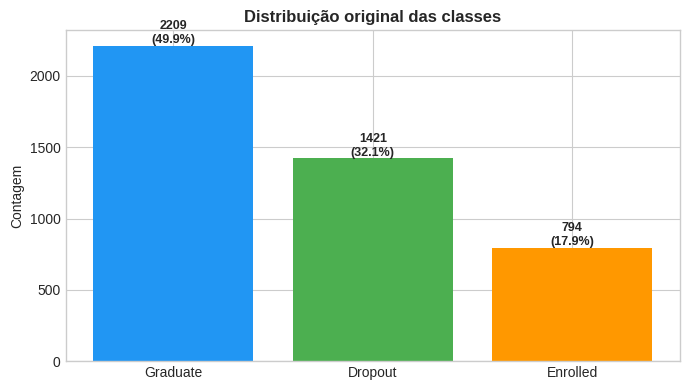


 Target binarizado (1=Evadido, 0=Não Evadido)
✓ percentual_curso_concluido criado (sem leakage). 100% aprovados no 1º ano: 1280 (28.9%)
 Shape final de X: (4424, 35) (35 atributos preditores)

 Split triplo — Treino (2654, 35) | Val (885, 35) | Teste (885, 35)
  Dist. Treino    : Counter({0: 1801, 1: 853})
  Dist. Validação : Counter({0: 601, 1: 284})
  Dist. Teste     : Counter({0: 601, 1: 284})

Contaminação baseline: 0.3214


In [6]:
# %% [CÉLULA 6] Pré-processamento, Engenharia de Atributos e Particionamento 60/20/20 Sem Vazamento
class DataPreprocessor:
    # Hash SHA-256 congelado da base oficial
    EXPECTED_SHA256 = 'ff327a7ed348140d42dd682df49e36331e2ca91ca41b8fb9ad911a4f5fba0f4e'

    def __init__(self, path, seed=42):
        self.data_path = path
        self.seed = seed
        self.df = self.X = self.y = self.feature_names = self.scaler = None
        self.cat_encoders = {}

    def load_data(self):
        try:
            with open(self.data_path, 'rb') as f:
                sha = hashlib.sha256(f.read()).hexdigest()
            if self.EXPECTED_SHA256 is None:
                print(f'  ℹ SHA-256 = {sha}  (copie para EXPECTED_SHA256 no artigo)')
            elif sha == self.EXPECTED_SHA256:
                print(f' SHA-256 verificado ({sha[:16]}...).')
            else:
                print(f'⚠ SHA-256 diverge: {sha[:16]}...')
        except Exception as e:
            print(f'⚠ SHA-256: {e}')
        try:
            try:
                self.df = pd.read_csv(self.data_path, delimiter=';')
                if 'Target' not in self.df.columns:
                    raise ValueError()
            except Exception:
                self.df = pd.read_csv(self.data_path, delimiter=',')
            self.df.columns = self.df.columns.str.strip().str.replace('"', '')
            print(f' {self.df.shape[0]} linhas × {self.df.shape[1]} colunas carregadas')
            return 'Target' in self.df.columns
        except FileNotFoundError:
            print(f' {self.data_path}')
            return False

    def explore(self):
        print('\n--- Distribuição original ---')
        print(self.df['Target'].value_counts())
        fig, ax = plt.subplots(figsize=(7, 4))
        tc = self.df['Target'].value_counts()
        bars = ax.bar(tc.index, tc.values, color=['#2196F3', '#4CAF50', '#FF9800'])
        for bar, val in zip(bars, tc.values):
            ax.text(bar.get_x() + bar.get_width() / 2, val + 20,
                    f'{val}\n({val / len(self.df) * 100:.1f}%)',
                    ha='center', fontweight='bold', fontsize=9)
        ax.set_title('Distribuição original das classes', fontweight='bold')
        ax.set_ylabel('Contagem')
        plt.tight_layout()
        plt.savefig(caminho_saida('eda_distribuicao_classes.png', 'figuras'),
                    dpi=150, bbox_inches='tight')
        plt.show()

    def preprocess(self):
        self.df['Target'] = self.df['Target'].map(
            {'Dropout': 1, 'Enrolled': 0, 'Graduate': 0, 1: 1, 0: 0}
        )
        print('\n Target binarizado (1=Evadido, 0=Não Evadido)')
        self.y = self.df['Target'].copy()
        self.X = self.df.drop('Target', axis=1).copy()

        cols = [
            'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)',
            'Curricular units 1st sem (enrolled)', 'Curricular units 2nd sem (enrolled)'
        ]
        if all(c in self.X.columns for c in cols):
            a1, a2, m1, m2 = cols
            ap = self.X[a1] + self.X[a2]
            mt = self.X[m1] + self.X[m2]
            aproveitamento_total = (mt > 0) & (ap >= mt)
            razao = np.where(mt > 0, ap / mt, 0.0)
            razao = np.clip(razao, 0.0, 0.99)
            self.X['percentual_curso_concluido'] = np.where(aproveitamento_total, 1.0, razao)
            print(f'✓ percentual_curso_concluido criado (sem leakage). '
                  f'100% aprovados no 1º ano: {aproveitamento_total.sum()} '
                  f'({aproveitamento_total.mean() * 100:.1f}%)')

        self.feature_names = self.X.columns.tolist()
        for col in self.X.columns:
            if self.X[col].dtype == 'object':
                le = LabelEncoder()
                self.X[col] = le.fit_transform(self.X[col].astype(str))
                self.cat_encoders[col] = le
        print(f' Shape final de X: {self.X.shape} (35 atributos preditores)')

    def split_and_scale(self, test_size=0.20, val_size=0.25):
        X_temp, X_test_raw, y_temp, y_test = train_test_split(
            self.X, self.y, test_size=test_size, stratify=self.y, random_state=self.seed
        )
        X_train_raw, X_val_raw, y_train, y_val = train_test_split(
            X_temp, y_temp, test_size=val_size, stratify=y_temp, random_state=self.seed
        )

        # Imputação defensiva de mediana calculada estritamente no Treino (sem data leakage)
        if X_train_raw.isnull().sum().sum() > 0 or X_val_raw.isnull().sum().sum() > 0 or X_test_raw.isnull().sum().sum() > 0:
            print('⚠ NaN detectado: imputação por mediana ajustada exclusivamente no conjunto de treino.')
            mediana_treino = X_train_raw.median()
            X_train_raw = X_train_raw.fillna(mediana_treino)
            X_val_raw   = X_val_raw.fillna(mediana_treino)
            X_test_raw  = X_test_raw.fillna(mediana_treino)

        # StandardScaler ajustado estritamente nos dados de treino
        self.scaler = StandardScaler().fit(X_train_raw)
        X_train = self.scaler.transform(X_train_raw)
        X_val   = self.scaler.transform(X_val_raw)
        X_test  = self.scaler.transform(X_test_raw)

        print(f'\n Split triplo — Treino {X_train.shape} | Val {X_val.shape} | Teste {X_test.shape}')
        print(f'  Dist. Treino    : {Counter(y_train)}')
        print(f'  Dist. Validação : {Counter(y_val)}')
        print(f'  Dist. Teste     : {Counter(y_test)}')
        return (X_train, X_val, X_test, y_train.values, y_val.values, y_test.values,
                X_train_raw, X_val_raw, X_test_raw)


preprocessor = DataPreprocessor(DATASET_PATH, SEED)
if preprocessor.load_data():
    preprocessor.explore()
    preprocessor.preprocess()
    (X_train, X_val, X_test, y_train, y_val, y_test,
     X_train_raw, X_val_raw, X_test_raw) = preprocessor.split_and_scale()
    feature_names = preprocessor.feature_names
    scaler = preprocessor.scaler
    X_train_normal = X_train[y_train == 0]
    contamination_rate = max(0.01, float((y_train == 1).sum()) / len(y_train))
    print(f'\nContaminação baseline: {contamination_rate:.4f}')
    DATA_READY = True
else:
    DATA_READY = False

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0000,1.1786,0.6057,1.0000,1.0000,1.0000,1.0000,6.0000
Application mode,4424.0000,6.8870,5.2990,1.0000,1.0000,8.0000,12.0000,18.0000
Application order,4424.0000,1.7278,1.3138,0.0000,1.0000,1.0000,2.0000,9.0000
Course,4424.0000,9.8992,4.3318,1.0000,6.0000,10.0000,13.0000,17.0000
Daytime/evening attendance,4424.0000,0.8908,0.3119,0.0000,1.0000,1.0000,1.0000,1.0000
Previous qualification,4424.0000,2.5314,3.9637,1.0000,1.0000,1.0000,1.0000,17.0000
Nacionality,4424.0000,1.2545,1.7484,1.0000,1.0000,1.0000,1.0000,21.0000
Mother's qualification,4424.0000,12.3221,9.0263,1.0000,2.0000,13.0000,22.0000,29.0000
Father's qualification,4424.0000,16.4552,11.0448,1.0000,3.0000,14.0000,27.0000,34.0000
Mother's occupation,4424.0000,7.3178,3.9978,1.0000,5.0000,6.0000,10.0000,32.0000


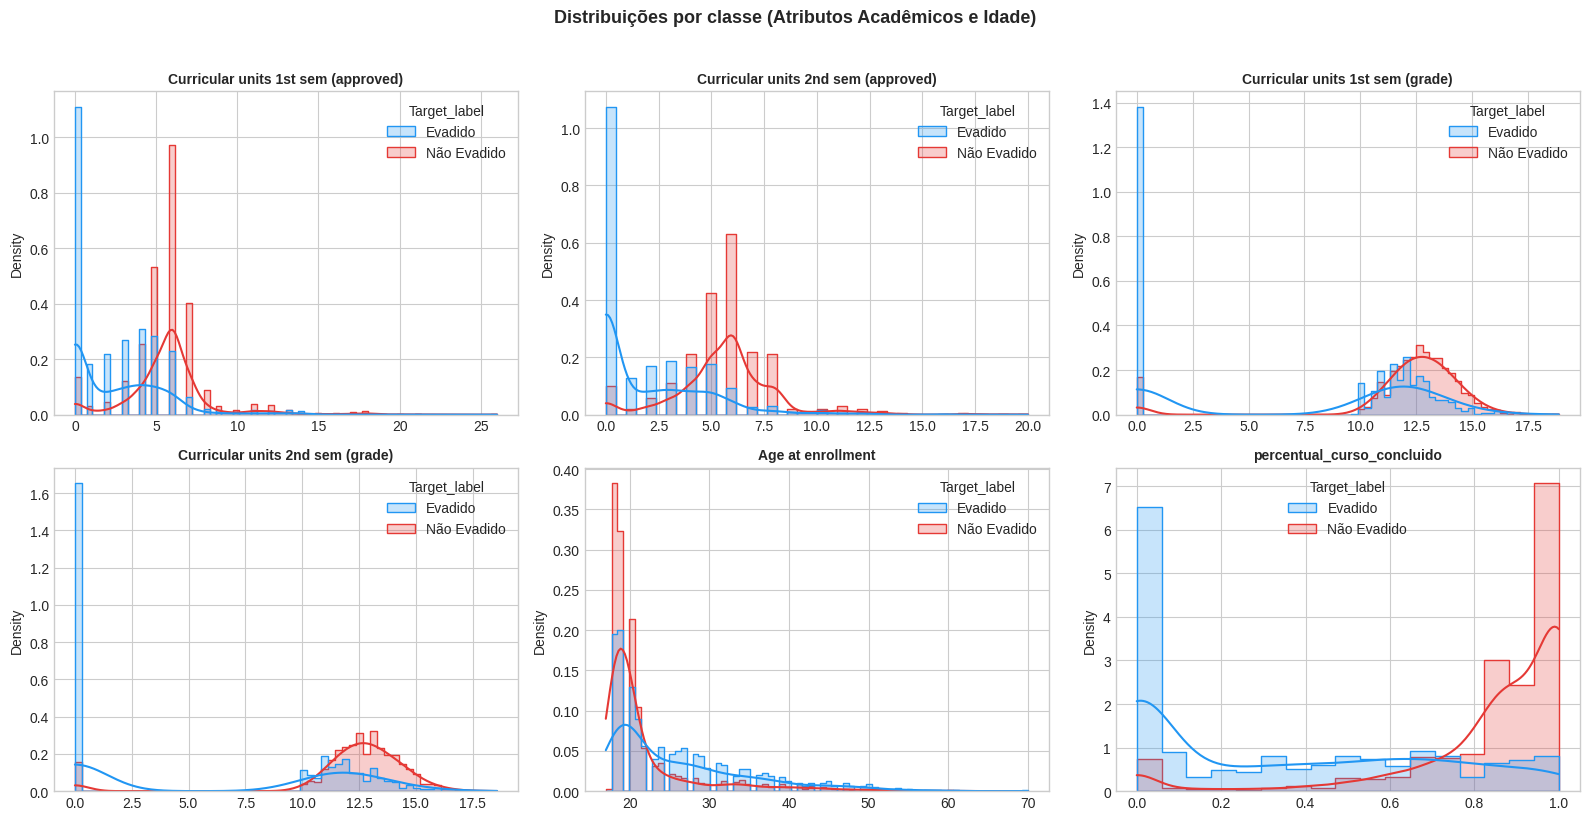

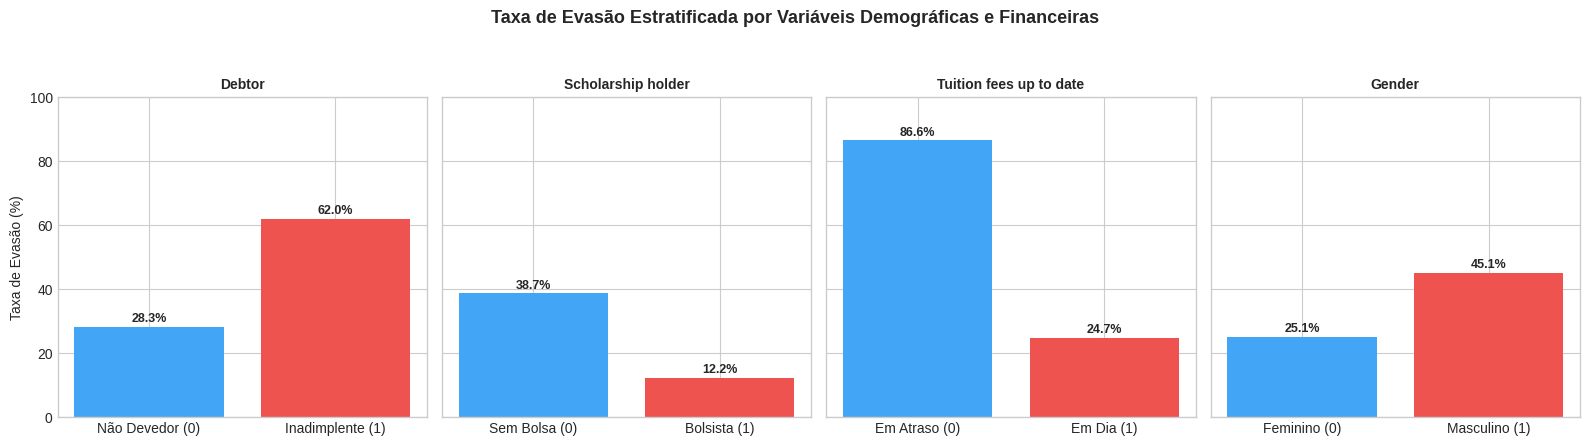

In [7]:
# %% [CÉLULA 7] Análise Exploratória de Dados
if DATA_READY:
    df_eda = preprocessor.X.copy()
    df_eda['Target'] = preprocessor.y.values
    df_eda['Target_label'] = df_eda['Target'].map({0: 'Não Evadido', 1: 'Evadido'})
    display(df_eda.drop(columns=['Target_label']).describe().T)
    df_eda.drop(columns=['Target_label']).describe().T.to_csv(
        caminho_saida('eda_describe.csv', 'tabelas')
    )

    # --- FIGURA 1: Distribuições Acadêmicas ---
    vars_acad = [
        'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)',
        'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)',
        'Age at enrollment', 'percentual_curso_concluido'
    ]
    vars_acad = [v for v in vars_acad if v in df_eda.columns]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    axes = axes.ravel()
    for i, col in enumerate(vars_acad):
        sns.histplot(
            data=df_eda, x=col, hue='Target_label', kde=True,
            element='step', stat='density', common_norm=False,
            ax=axes[i], palette=['#2196F3', '#E53935']
        )
        axes[i].set_title(col, fontsize=10, fontweight='bold')
        axes[i].set_xlabel('')
    plt.suptitle('Distribuições por classe (Atributos Acadêmicos e Idade)', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(caminho_saida('eda_distribuicoes_academicas.png', 'figuras'),
                dpi=200, bbox_inches='tight')
    plt.show()

    # --- FIGURA 2: Taxa de Evasão por Variáveis Categóricas Sociodemográficas (Seção 3.2) ---
    vars_demo = {
        'Debtor': {0: 'Não Devedor (0)', 1: 'Inadimplente (1)'},
        'Scholarship holder': {0: 'Sem Bolsa (0)', 1: 'Bolsista (1)'},
        'Tuition fees up to date': {0: 'Em Atraso (0)', 1: 'Em Dia (1)'},
        'Gender': {0: 'Feminino (0)', 1: 'Masculino (1)'}
    }
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
    for i, (col, mapa) in enumerate(vars_demo.items()):
        if col in df_eda.columns:
            taxas = df_eda.groupby(col)['Target'].mean() * 100
            labels_cat = [mapa.get(k, str(k)) for k in taxas.index]
            bars = axes[i].bar(labels_cat, taxas.values, color=['#42A5F5', '#EF5350'][:len(taxas)])
            for bar, v in zip(bars, taxas.values):
                axes[i].text(bar.get_x() + bar.get_width() / 2, v + 1.5,
                             f'{v:.1f}%', ha='center', fontweight='bold', fontsize=9)
            axes[i].set_title(col, fontsize=10, fontweight='bold')
            axes[i].set_ylim(0, 100)
            if i == 0:
                axes[i].set_ylabel('Taxa de Evasão (%)')
    plt.suptitle('Taxa de Evasão Estratificada por Variáveis Demográficas e Financeiras',
                 fontsize=13, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.savefig(caminho_saida('eda_taxa_evasao_demografico.png', 'figuras'),
                dpi=200, bbox_inches='tight')
    plt.show()

In [8]:
# %% [CÉLULA 8] Funções de Avaliação, Testes Estatísticos, Calibração, DCA, Fairness e Duas Camadas
if DATA_READY:

    def evaluate_model(model_name, abordagem, y_true, y_pred, y_prob=None,
                       training_time=0.0, plot_cm=True, save_prefix='v4',
                       prob_calibrated=True):
        try:
            f1 = f1_score(y_true, y_pred, zero_division=0)
            rec = recall_score(y_true, y_pred, zero_division=0)
            prec = precision_score(y_true, y_pred, zero_division=0)
            acc = accuracy_score(y_true, y_pred)
            mcc = matthews_corrcoef(y_true, y_pred)
            bacc = balanced_accuracy_score(y_true, y_pred)
            kappa = cohen_kappa_score(y_true, y_pred)
            cm = confusion_matrix(y_true, y_pred)
            tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)
            spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
            gmean = np.sqrt(rec * spec) if (rec * spec) >= 0 else 0.0

            if y_prob is not None:
                roc_auc = roc_auc_score(y_true, y_prob)
                pr_auc  = average_precision_score(y_true, y_prob)
                if prob_calibrated:
                    brier = brier_score_loss(y_true, np.clip(y_prob, 0.0, 1.0))
                    try:
                        logloss = log_loss(y_true, np.clip(y_prob, 1e-15, 1 - 1e-15))
                    except Exception:
                        logloss = np.nan
                else:
                    brier, logloss = np.nan, np.nan
            else:
                roc_auc = roc_auc_score(y_true, y_pred)
                pr_auc, brier, logloss = 0.0, np.nan, np.nan

            metrics = {
                'Model': model_name, 'Abordagem': abordagem,
                'F1-Score': round(f1, 4), 'Recall': round(rec, 4),
                'Precision': round(prec, 4), 'Accuracy': round(acc, 4),
                'BalancedAcc': round(bacc, 4), 'Specificity': round(spec, 4),
                'G-Mean': round(gmean, 4), 'MCC': round(mcc, 4),
                'Kappa': round(kappa, 4), 'AUC-ROC': round(roc_auc, 4),
                'AUC-PR': round(pr_auc, 4),
                'Brier': round(brier, 4) if not np.isnan(brier) else np.nan,
                'LogLoss': round(logloss, 4) if not np.isnan(logloss) else np.nan,
                'Training Time': round(training_time, 2),
                'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)
            }
            print(f'\n{"="*55}\n  Modelo: {model_name}\n{"="*55}')
            print(f'  F1={f1:.4f}  Recall={rec:.4f}  Precision={prec:.4f}  Acc={acc:.4f}')
            print(f'  AUC-ROC={roc_auc:.4f}  AUC-PR={pr_auc:.4f}  Brier={brier if not np.isnan(brier) else -1:.4f}')
            print(f'  MCC={mcc:.4f}  Kappa={kappa:.4f}  G-Mean={gmean:.4f}')
            print(f'  TP={tp} FP={fp} FN={fn} TN={tn}  Tempo={training_time:.2f}s')

            preds_store[model_name] = {
                'y_pred': np.asarray(y_pred).astype(int),
                'y_prob': None if y_prob is None else np.asarray(y_prob, dtype=float),
                'prob_calibrated': bool(prob_calibrated),
                'abordagem': abordagem
            }
        except Exception as e:
            print(f' {model_name}: {e}')
            traceback.print_exc()
            return None

        if plot_cm:
            try:
                fig, ax = plt.subplots(figsize=(5, 4))
                ConfusionMatrixDisplay(
                    confusion_matrix=cm,
                    display_labels=['Não Evadido', 'Evadido']
                ).plot(ax=ax, cmap='Blues', colorbar=False)
                ax.set_title(f'Matriz de Confusão — {model_name}', fontsize=11, fontweight='bold')
                plt.tight_layout()
                safe = model_name.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '').replace('+', '')
                plt.savefig(caminho_saida(f'cm_{save_prefix}_{safe}.png', 'figuras'),
                            dpi=150, bbox_inches='tight')
                plt.show()
            except Exception as e:
                print(f'  ⚠ CM: {e}')
        return metrics

    # --- Bootstrap pareado vetorizado ---
    def _metrics_from_counts(tp, fp, fn, tn):
        tp, fp, fn, tn = [np.asarray(v, dtype=float) for v in (tp, fp, fn, tn)]
        with np.errstate(divide='ignore', invalid='ignore'):
            prec = np.where(tp + fp > 0, tp / (tp + fp), 0.0)
            rec  = np.where(tp + fn > 0, tp / (tp + fn), 0.0)
            spec = np.where(tn + fp > 0, tn / (tn + fp), 0.0)
            f1   = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), 0.0)
            den  = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
            mcc  = np.where(den > 0, (tp * tn - fp * fn) / den, 0.0)
        return {'F1': f1, 'Recall': rec, 'Precision': prec, 'Specificity': spec,
                'MCC': mcc, 'BalancedAcc': (rec + spec) / 2.0}

    def paired_bootstrap(y_true, preds_dict, n_boot=2000, seed=SEED):
        y_true = np.asarray(y_true).astype(int)
        n = len(y_true)
        rng = np.random.RandomState(seed)
        idx = rng.randint(0, n, size=(n_boot, n))
        yt = y_true[idx]
        m_pos = yt.sum(axis=1).astype(float)
        m_neg = n - m_pos
        valid = (m_pos > 0) & (m_neg > 0)
        out = {}
        for name, d in preds_dict.items():
            yp = np.asarray(d['y_pred']).astype(int)[idx]
            tp = ((yt == 1) & (yp == 1)).sum(axis=1)
            fp = ((yt == 0) & (yp == 1)).sum(axis=1)
            fn = ((yt == 1) & (yp == 0)).sum(axis=1)
            tn = ((yt == 0) & (yp == 0)).sum(axis=1)
            res = _metrics_from_counts(tp, fp, fn, tn)
            if d.get('y_prob') is not None:
                pr = np.asarray(d['y_prob'], dtype=float)[idx]
                ranks = stats.rankdata(pr, axis=1)
                with np.errstate(divide='ignore', invalid='ignore'):
                    res['AUC-ROC'] = ((ranks * (yt == 1)).sum(axis=1)
                                      - m_pos * (m_pos + 1) / 2.0) / (m_pos * m_neg)
            for k in res:
                res[k] = np.where(valid, res[k], np.nan)
            out[name] = res
        return out

    def summarize_bootstrap(arr, alpha=0.05):
        a = np.asarray(arr)
        a = a[~np.isnan(a)]
        lo, hi = np.percentile(a, [100 * alpha / 2.0, 100 * (1.0 - alpha / 2.0)])
        return float(np.mean(a)), float(lo), float(hi)

    def paired_delta_pvalue(delta):
        d = np.asarray(delta)
        d = d[~np.isnan(d)]
        p = 2.0 * min((np.sum(d <= 0) + 1) / (len(d) + 1), (np.sum(d >= 0) + 1) / (len(d) + 1))
        return float(min(p, 1.0))

    # --- Teste de DeLong (com proteção numérica contra variância nula) ---
    def _compute_midrank(x):
        J = np.argsort(x)
        Z = x[J]
        N = len(x)
        T = np.zeros(N, dtype=float)
        i = 0
        while i < N:
            j = i
            while j < N and Z[j] == Z[i]:
                j += 1
            T[i:j] = 0.5 * (i + j - 1) + 1
            i = j
        T2 = np.empty(N, dtype=float)
        T2[J] = T
        return T2

    def _fast_delong(preds_sorted, m):
        n = preds_sorted.shape[1] - m
        pos = preds_sorted[:, :m]
        neg = preds_sorted[:, m:]
        k = preds_sorted.shape[0]
        tx = np.empty([k, m])
        ty = np.empty([k, n])
        tz = np.empty([k, m + n])
        for r in range(k):
            tx[r, :] = _compute_midrank(pos[r, :])
            ty[r, :] = _compute_midrank(neg[r, :])
            tz[r, :] = _compute_midrank(preds_sorted[r, :])
        aucs = tz[:, :m].sum(axis=1) / m / n - float(m + 1) / 2.0 / n
        v01 = (tz[:, :m] - tx) / n
        v10 = 1.0 - (tz[:, m:] - ty) / m
        sx = np.cov(v01)
        sy = np.cov(v10)
        return aucs, sx / m + sy / n

    def delong_test(y_true, s1, s2):
        order = np.argsort(-y_true)
        yt = np.asarray(y_true)[order]
        preds = np.vstack([np.asarray(s1)[order], np.asarray(s2)[order]])
        m = int(yt.sum())
        aucs, cov = _fast_delong(preds, m)
        L = np.array([[1.0, -1.0]])
        denom = float(np.sqrt(max(0.0, float((L @ cov @ L.T).item()))))
        if denom <= 1e-12:
            return float(aucs[0]), float(aucs[1]), 0.0, 1.0
        z = float((L @ aucs).item() / denom)
        p = float(2.0 * (1.0 - stats.norm.cdf(abs(z))))
        return float(aucs[0]), float(aucs[1]), z, p

    # --- McNemar + Correção de Holm-Bonferroni ---
    def holm_correction(p):
        p = np.asarray(p, dtype=float)
        n = len(p)
        order = np.argsort(p)
        adj = np.empty(n)
        running = 0.0
        for rank, idx in enumerate(order):
            val = (n - rank) * p[idx]
            running = max(running, val)
            adj[idx] = running
        return np.minimum(adj, 1.0)

    def mcnemar_test(y_true, p1, p2):
        y_true = np.asarray(y_true)
        c1 = (p1 == y_true)
        c2 = (p2 == y_true)
        table = [
            [int(np.sum(c1 & c2)), int(np.sum(c1 & ~c2))],
            [int(np.sum(~c1 & c2)), int(np.sum(~c1 & ~c2))]
        ]
        nd = table[0][1] + table[1][0]
        if nd == 0:
            return 0.0, 1.0
        res = mcnemar(table, exact=(nd < 25), correction=True)
        return float(res.statistic), float(res.pvalue)

    # --- Curva de Calibração e Decision Curve Analysis (DCA) ---
    def calibration_plot(y_true, prob_list, name_list, n_bins=10, fname='calibracao.png'):
        fig, ax = plt.subplots(figsize=(6, 5))
        ax.plot([0, 1], [0, 1], 'k--', label='Perfeitamente Calibrado')
        for p, n in zip(prob_list, name_list):
            try:
                p_clip = np.clip(np.asarray(p, dtype=float), 0.0, 1.0)
                frac, mp = calibration_curve(y_true, p_clip, n_bins=n_bins, strategy='quantile')
                ax.plot(mp, frac, marker='o', linewidth=1.8, label=n)
            except Exception:
                pass
        ax.set_xlabel('Probabilidade Prevista / Score Normalizado')
        ax.set_ylabel('Fração de Positivos Observada')
        ax.set_title('Curva de Calibração (Reliability Diagram)', fontweight='bold')
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(caminho_saida(fname, 'figuras'), dpi=200, bbox_inches='tight')
        plt.show()

    def decision_curve_analysis(y_true, prob_list, name_list,
                                thresholds=np.arange(0.01, 0.99, 0.01), fname='dca.png'):
        y_true = np.asarray(y_true)
        n = len(y_true)
        prev = y_true.mean()
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.plot(thresholds, [prev - (1.0 - prev) * (pt / (1.0 - pt)) for pt in thresholds],
                'k-', label='Intervir em todos')
        ax.axhline(0, color='gray', linestyle='--', label='Não intervir em ninguém')
        for prob, name in zip(prob_list, name_list):
            p_clip = np.clip(np.asarray(prob, dtype=float), 0.0, 1.0)
            nb = []
            for pt in thresholds:
                pred = (p_clip >= pt).astype(int)
                tp = np.sum((pred == 1) & (y_true == 1))
                fp = np.sum((pred == 1) & (y_true == 0))
                nb.append(tp / n - (fp / n) * (pt / (1.0 - pt)))
            ax.plot(thresholds, nb, linewidth=1.8, label=name)
        ax.set_xlim(0, 0.6)
        ax.set_ylim(-0.05, prev + 0.05)
        ax.set_xlabel('Limiar de Probabilidade / Tolerância de Risco (Threshold)')
        ax.set_ylabel('Benefício Líquido (Net Benefit)')
        ax.set_title('Decision Curve Analysis (DCA)', fontweight='bold')
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(caminho_saida(fname, 'figuras'), dpi=200, bbox_inches='tight')
        plt.show()

    # --- Utilitários One-Class (Escalonamento Min-Max de Scores para [0, 1]) ---
    def fit_score_range(s):
        s = np.asarray(s, dtype=float)
        return float(s.min()), float(s.max())

    def apply_score_range(s, r):
        mn, mx = r
        s = np.asarray(s, dtype=float)
        return np.zeros_like(s) if mx == mn else np.clip((s - mn) / (mx - mn), 0.0, 1.0)

    # --- ADIÇÃO: Expected Calibration Error (ECE) e Curvas ROC + PR Lado a Lado ---
    def compute_ece(y_true, y_prob, n_bins=10):
        y_true = np.asarray(y_true)
        y_prob = np.clip(np.asarray(y_prob, dtype=float), 0.0, 1.0)
        bins = np.linspace(0.0, 1.0, n_bins + 1)
        bin_ids = np.digitize(y_prob, bins[1:-1], right=True)
        ece = 0.0
        n = len(y_true)
        for b in range(n_bins):
            mask = (bin_ids == b)
            if np.any(mask):
                acc_bin = y_true[mask].mean()
                conf_bin = y_prob[mask].mean()
                ece += (mask.sum() / n) * abs(acc_bin - conf_bin)
        return float(ece)

    def plot_roc_and_pr_curves(y_true, model_names, fname='roc_pr_comparativo.png'):
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        prev = np.mean(y_true)
        for name in model_names:
            if name not in preds_store or preds_store[name]['y_prob'] is None:
                continue
            prob = preds_store[name]['y_prob']
            fpr, tpr, _ = roc_curve(y_true, prob)
            prec, rec, _ = precision_recall_curve(y_true, prob)
            auc_r = roc_auc_score(y_true, prob)
            auc_p = average_precision_score(y_true, prob)
            axes[0].plot(fpr, tpr, lw=1.8, label=f'{name} (AUC={auc_r:.3f})')
            axes[1].plot(rec, prec, lw=1.8, label=f'{name} (PR-AUC={auc_p:.3f})')
        axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatório (0.500)')
        axes[0].set_title('Curvas ROC (Conjunto de Teste)', fontweight='bold')
        axes[0].set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
        axes[0].set_ylabel('Sensibilidade (Recall)')
        axes[0].legend(fontsize=8)
        axes[1].axhline(prev, color='k', linestyle='--', lw=1, label=f'Baseline ({prev:.3f})')
        axes[1].set_title('Curvas Precision-Recall (Conjunto de Teste)', fontweight='bold')
        axes[1].set_xlabel('Recall (Sensibilidade)')
        axes[1].set_ylabel('Precision (Valor Preditivo Positivo)')
        axes[1].legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(caminho_saida(fname, 'figuras'), dpi=200, bbox_inches='tight')
        plt.show()

    # --- ADIÇÃO: Estudo de Ablação sobre 'percentual_curso_concluido' ---
    def ablation_feature_sintetica(model_builder_fn, X_tr, y_tr, X_te, y_te, feature_names, seeds=SEEDS_ABLACAO):
        idx_sint = feature_names.index('percentual_curso_concluido')
        mask_34 = [i for i in range(len(feature_names)) if i != idx_sint]
        resultados_abl = []
        for cenario, cols in [('Com Feature Sintética (35 atr.)', slice(None)),
                              ('Sem Feature Sintética (34 atr.)', mask_34)]:
            mccs, f1s = [], []
            for s in seeds:
                clf = model_builder_fn(s)
                clf.fit(X_tr[:, cols], y_tr)
                pred = clf.predict(X_te[:, cols])
                mccs.append(matthews_corrcoef(y_te, pred))
                f1s.append(f1_score(y_te, pred))
            resultados_abl.append({
                'Cenário': cenario,
                'MCC (Média ± DP)': f'{np.mean(mccs):.4f} ± {np.std(mccs):.4f}',
                'F1-Score (Média ± DP)': f'{np.mean(f1s):.4f} ± {np.std(f1s):.4f}'
            })
        df_abl = pd.DataFrame(resultados_abl)
        df_abl.to_csv(caminho_saida('ablacao_feature_sintetica.csv', 'tabelas'), index=False)
        display(df_abl)
        return df_abl

    # --- ADIÇÃO: Auditoria de Equidade e Disparate Impact (Seção 5.2) ---
    def fairness_audit(X_test_raw_df, y_true, preds_store, model_names):
        grupos_sensiveis = {
            'Gender (Masculino=1 vs Feminino=0)': (X_test_raw_df['Gender'] == 1),
            'Debtor (Inadimplente=1 vs Em dia=0)': (X_test_raw_df['Debtor'] == 1),
            'Scholarship (Sem Bolsa=0 vs Bolsista=1)': (X_test_raw_df['Scholarship holder'] == 0),
            'Age (Ingresso Tardio >=25 vs <25)': (X_test_raw_df['Age at enrollment'] >= 25)
        }
        rows = []
        for g_nome, mask_vuln in grupos_sensiveis.items():
            mask_vuln = np.asarray(mask_vuln, dtype=bool)
            mask_priv = ~mask_vuln
            for m in model_names:
                if m not in preds_store:
                    continue
                yp = preds_store[m]['y_pred']
                sr_vuln = yp[mask_vuln].mean()
                sr_priv = yp[mask_priv].mean()
                di_ratio = sr_vuln / sr_priv if sr_priv > 0 else np.nan
                neg_vuln = mask_vuln & (y_true == 0)
                neg_priv = mask_priv & (y_true == 0)
                fpr_vuln = yp[neg_vuln].mean() if neg_vuln.sum() > 0 else 0.0
                fpr_priv = yp[neg_priv].mean() if neg_priv.sum() > 0 else 0.0
                rows.append({
                    'Recorte Demográfico / Social': g_nome,
                    'Modelo': m,
                    'Selection Rate (Vulnerável)': round(sr_vuln, 4),
                    'Selection Rate (Referência)': round(sr_priv, 4),
                    'Disparate Impact Ratio': round(di_ratio, 4),
                    'FPR (Vulnerável)': round(fpr_vuln, 4),
                    'FPR (Referência)': round(fpr_priv, 4),
                    'Diferença de FPR (Estigma)': round(fpr_vuln - fpr_priv, 4)
                })
        df_fairness = pd.DataFrame(rows)
        df_fairness.to_csv(caminho_saida('auditoria_fairness_disparate_impact.csv', 'tabelas'), index=False)
        display(df_fairness)
        return df_fairness

    # --- ADIÇÃO: Simulação da Matriz de Gestão em Duas Camadas (Seção 6) ---
    def simular_sistema_duas_camadas(y_true, pred_sup, pred_occ, nome_sup='Supervisionado', nome_occ='One-Class'):
        y_true = np.asarray(y_true)
        p_sup  = np.asarray(pred_sup)
        p_occ  = np.asarray(pred_occ)
        quadrantes = {
            'Q1: Risco Duplo (Tutoria + Assistência Social)': (p_sup == 1) & (p_occ == 1),
            'Q2: Risco Acadêmico Puro (Foco em Tutoria/Monitoria)': (p_sup == 1) & (p_occ == 0),
            'Q3: Vulnerabilidade Estrutural Silenciosa (Radar Social)': (p_sup == 0) & (p_occ == 1),
            'Q4: Baixo Risco Global (Acompanhamento Regular)': (p_sup == 0) & (p_occ == 0)
        }
        resumo = []
        for q_nome, mask in quadrantes.items():
            n_alunos = int(mask.sum())
            evadidos_reais = int(y_true[mask].sum()) if n_alunos > 0 else 0
            taxa_evasao = (evadidos_reais / n_alunos * 100) if n_alunos > 0 else 0.0
            resumo.append({
                'Quadrante de Intervenção': q_nome,
                'Total de Alunos (Teste)': n_alunos,
                '% da Coorte': round(n_alunos / len(y_true) * 100, 1),
                'Evadidos Reais Capturados': evadidos_reais,
                'Taxa Real de Evasão no Grupo (%)': round(taxa_evasao, 1)
            })
        df_quad = pd.DataFrame(resumo)
        df_quad.to_csv(caminho_saida('simulacao_sistema_duas_camadas.csv', 'tabelas'), index=False)
        display(df_quad)
        return df_quad

    print(' Funções de avaliação, estatística, calibração, DCA, Fairness e Duas Camadas prontas.')

 Funções de avaliação, estatística, calibração, DCA, Fairness e Duas Camadas prontas.


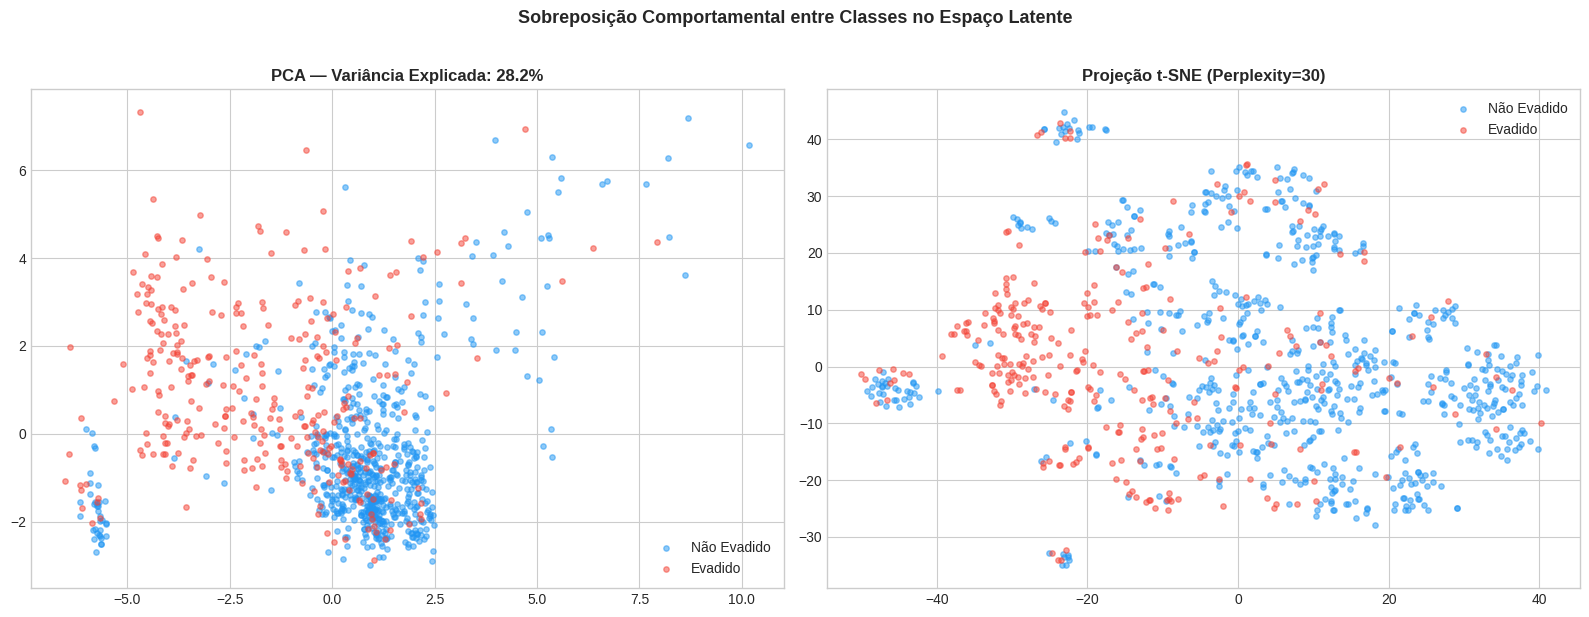

In [9]:
# %% [CÉLULA 9] Projeção e Topologia do Espaço de Características
if DATA_READY:
    n_viz = min(1000, X_train.shape[0])
    idx = np.random.RandomState(SEED).choice(X_train.shape[0], n_viz, replace=False)
    X_viz, y_viz = X_train[idx], y_train[idx]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    colors = {0: '#2196F3', 1: '#F44336'}
    labels = {0: 'Não Evadido', 1: 'Evadido'}

    pca = PCA(n_components=2, random_state=SEED)
    X_pca = pca.fit_transform(X_viz)
    for cls in [0, 1]:
        m = y_viz == cls
        axes[0].scatter(X_pca[m, 0], X_pca[m, 1], c=colors[cls], label=labels[cls], alpha=0.5, s=15)
    axes[0].set_title(f'PCA — Variância Explicada: {pca.explained_variance_ratio_.sum() * 100:.1f}%',
                      fontweight='bold')
    axes[0].legend()

    tsne = TSNE(n_components=2, perplexity=30, **{TSNE_ITER_KW: 1000},
                learning_rate='auto', init='pca', random_state=SEED)
    X_tsne = tsne.fit_transform(X_viz)
    for cls in [0, 1]:
        m = y_viz == cls
        axes[1].scatter(X_tsne[m, 0], X_tsne[m, 1], c=colors[cls], label=labels[cls], alpha=0.5, s=15)
    axes[1].set_title('Projeção t-SNE (Perplexity=30)', fontweight='bold')
    axes[1].legend()

    plt.suptitle('Sobreposição Comportamental entre Classes no Espaço Latente',
                 fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(caminho_saida('tsne_pca_2d.png', 'figuras'), dpi=300, bbox_inches='tight')
    plt.show()


  Modelo: Random Forest + SMOTE
  F1=0.8291  Recall=0.8028  Precision=0.8571  Acc=0.8938
  AUC-ROC=0.9333  AUC-PR=0.9054  Brier=0.0896
  MCC=0.7530  Kappa=0.7522  G-Mean=0.8672
  TP=228 FP=38 FN=56 TN=563  Tempo=89.92s


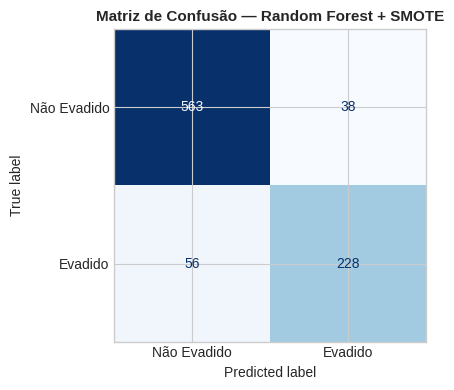


  Modelo: Random Forest + RandomOverSampler
  F1=0.8164  Recall=0.8063  Precision=0.8267  Acc=0.8836
  AUC-ROC=0.9330  AUC-PR=0.9034  Brier=0.0922
  MCC=0.7313  Kappa=0.7312  G-Mean=0.8614
  TP=229 FP=48 FN=55 TN=553  Tempo=51.16s

  Modelo: Random Forest + RandomUnderSampler
  F1=0.8066  Recall=0.8592  Precision=0.7601  Acc=0.8678
  AUC-ROC=0.9310  AUC-PR=0.9004  Brier=0.1034
  MCC=0.7098  Kappa=0.7068  G-Mean=0.8655
  TP=244 FP=77 FN=40 TN=524  Tempo=33.68s

  Modelo: Random Forest + NearMiss
  F1=0.7171  Recall=0.8838  Precision=0.6034  Acc=0.7763
  AUC-ROC=0.8948  AUC-PR=0.8413  Brier=0.1530
  MCC=0.5699  Kappa=0.5427  G-Mean=0.8007
  TP=251 FP=165 FN=33 TN=436  Tempo=36.19s

  Modelo: Random Forest + SMOTETomek
  F1=0.8094  Recall=0.7852  Precision=0.8352  Acc=0.8814
  AUC-ROC=0.9321  AUC-PR=0.9033  Brier=0.0908
  MCC=0.7241  Kappa=0.7234  G-Mean=0.8531
  TP=223 FP=44 FN=61 TN=557  Tempo=74.59s

  Modelo: Random Forest + SMOTEENN
  F1=0.8021  Recall=0.8204  Precision=0.7845  Acc=

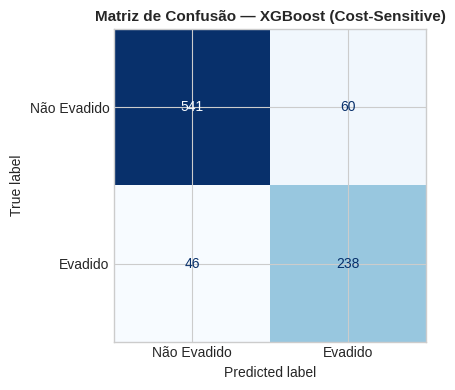

In [10]:
# %% [CÉLULA 10] Abordagem 1: Modelagem Supervisionada com Optuna e ImbPipeline
if DATA_READY:


    samplers_sup = {
        'Random Forest + SMOTE': lambda: SMOTE(random_state=SEED),
        'Random Forest + RandomOverSampler': lambda: RandomOverSampler(random_state=SEED),
        'Random Forest + RandomUnderSampler': lambda: RandomUnderSampler(random_state=SEED),
        'Random Forest + NearMiss': lambda: NearMiss(version=1),
        'Random Forest + SMOTETomek': lambda: SMOTETomek(random_state=SEED),
        'Random Forest + SMOTEENN': lambda: SMOTEENN(random_state=SEED)
    }

    for model_label, sampler_fn in samplers_sup.items():
        t0 = time.time()

        def objective_rf(trial):
            n_est = trial.suggest_int('n_estimators', 100, 400, step=50)
            m_depth = trial.suggest_int('max_depth', 5, 25)
            min_split = trial.suggest_int('min_samples_split', 2, 12)
            min_leaf = trial.suggest_int('min_samples_leaf', 1, 6)
            max_feat = trial.suggest_categorical('max_features', ['sqrt', 'log2'])

            # Pipeline encapsulando StandardScaler e reamostragem apenas sobre dados de treino
            pipe = ImbPipeline([
                ('scaler', StandardScaler()),
                ('sampler', sampler_fn()),
                ('clf', RandomForestClassifier(
                    n_estimators=n_est, max_depth=m_depth,
                    min_samples_split=min_split, min_samples_leaf=min_leaf,
                    max_features=max_feat, random_state=SEED, n_jobs=N_JOBS_CV
                ))
            ])
            pipe.fit(X_train_raw.values, y_train)
            preds_val = pipe.predict(X_val_raw.values)
            return f1_score(y_val, preds_val, zero_division=0)

        study_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
        study_rf.optimize(objective_rf, n_trials=N_TRIALS_SUP)
        bp = study_rf.best_params

        best_pipe = ImbPipeline([
            ('scaler', StandardScaler()),
            ('sampler', sampler_fn()),
            ('clf', RandomForestClassifier(
                n_estimators=bp['n_estimators'], max_depth=bp['max_depth'],
                min_samples_split=bp['min_samples_split'], min_samples_leaf=bp['min_samples_leaf'],
                max_features=bp['max_features'], random_state=SEED, n_jobs=N_JOBS_CV
            ))
        ])
        best_pipe.fit(X_train_raw.values, y_train)
        elapsed = time.time() - t0

        y_pred_test = best_pipe.predict(X_test_raw.values)
        y_prob_test = best_pipe.predict_proba(X_test_raw.values)[:, 1]

        models_store[model_label] = best_pipe
        met = evaluate_model(
            model_name=model_label, abordagem='Supervisionada',
            y_true=y_test, y_pred=y_pred_test, y_prob=y_prob_test,
            training_time=elapsed, plot_cm=(model_label == 'Random Forest + SMOTE'),
            prob_calibrated=True
        )
        if met:
            results_list.append(met)

    # --- XGBoost Baseline (Cost-Sensitive Learning via scale_pos_weight) ---
    t0 = time.time()
    base_pos_weight = float((y_train == 0).sum()) / max(1, int((y_train == 1).sum()))

    def objective_xgb(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 400, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.25, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 8),
            'scale_pos_weight': trial.suggest_float('scale_pos_weight', base_pos_weight * 0.7, base_pos_weight * 1.5),
            'random_state': SEED,
            'eval_metric': 'logloss',
            'n_jobs': N_JOBS_CV
        }
        clf = XGBClassifier(**params)
        clf.fit(X_train, y_train)
        preds_val = clf.predict(X_val)
        return f1_score(y_val, preds_val, zero_division=0)

    study_xgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_xgb.optimize(objective_xgb, n_trials=N_TRIALS_SUP)
    best_xgb = XGBClassifier(**study_xgb.best_params, random_state=SEED, eval_metric='logloss', n_jobs=N_JOBS_CV)
    best_xgb.fit(X_train, y_train)
    elapsed_xgb = time.time() - t0

    y_pred_xgb = best_xgb.predict(X_test)
    y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]
    models_store['XGBoost (Cost-Sensitive)'] = best_xgb
    met_xgb = evaluate_model(
        model_name='XGBoost (Cost-Sensitive)', abordagem='Supervisionada',
        y_true=y_test, y_pred=y_pred_xgb, y_prob=y_prob_xgb,
        training_time=elapsed_xgb, plot_cm=True, prob_calibrated=True
    )
    if met_xgb:
        results_list.append(met_xgb)

 Top-20 features selecionadas: ['percentual_curso_concluido', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)'] ...

  Modelo: OC-SVM
  F1=0.7684  Recall=0.7711  Precision=0.7657  Acc=0.8508
  AUC-ROC=0.8789  AUC-PR=0.7692  Brier=-1.0000
  MCC=0.6584  Kappa=0.6584  G-Mean=0.8277
  TP=219 FP=67 FN=65 TN=534  Tempo=22.27s


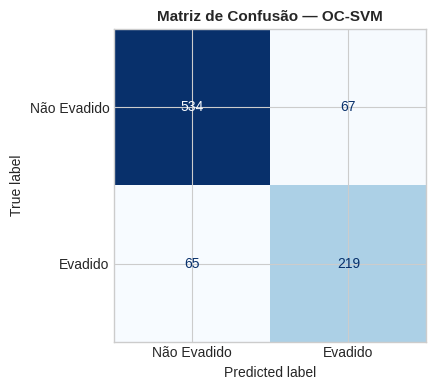


  Modelo: Isolation Forest
  F1=0.7267  Recall=0.7958  Precision=0.6686  Acc=0.8079
  AUC-ROC=0.8888  AUC-PR=0.8157  Brier=-1.0000
  MCC=0.5855  Kappa=0.5803  G-Mean=0.8047
  TP=226 FP=112 FN=58 TN=489  Tempo=46.55s


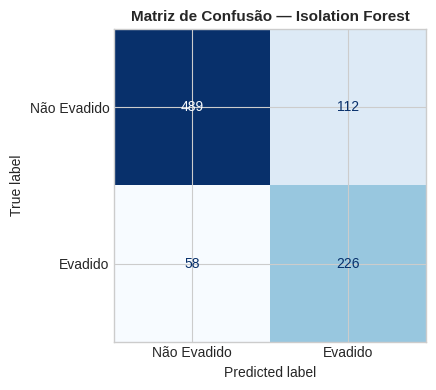


  Modelo: LOF
  F1=0.7296  Recall=0.6937  Precision=0.7695  Acc=0.8350
  AUC-ROC=0.8612  AUC-PR=0.7848  Brier=-1.0000
  MCC=0.6131  Kappa=0.6114  G-Mean=0.7909
  TP=197 FP=59 FN=87 TN=542  Tempo=19.13s

  Modelo: Autoencoder
  F1=0.7266  Recall=0.7254  Precision=0.7279  Acc=0.8249
  AUC-ROC=0.8713  AUC-PR=0.8149  Brier=-1.0000
  MCC=0.5978  Kappa=0.5978  G-Mean=0.7952
  TP=206 FP=77 FN=78 TN=524  Tempo=284.28s


In [11]:
# %% [CÉLULA 11] Abordagem 2: Seleção Top-20 Features e Detecção de Anomalias / One-Class
if DATA_READY:


    # Seleção das Top-20 features ajustada estritamente no conjunto de treino
    rf_selector = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=N_JOBS_CV)
    rf_selector.fit(X_train, y_train)
    importances_rf = rf_selector.feature_importances_
    top20_idx = np.argsort(importances_rf)[::-1][:TOP_K_OC_FEATURES]
    top20_names = [feature_names[i] for i in top20_idx]
    print(f' Top-{TOP_K_OC_FEATURES} features selecionadas: {top20_names[:5]} ...')

    X_train_norm_20 = X_train_normal[:, top20_idx]
    X_val_20        = X_val[:, top20_idx]
    X_test_20       = X_test[:, top20_idx]

    def optimize_dynamic_threshold(scores_val, y_val_true):
        percentis = np.linspace(5, 95, 181)
        best_th, best_f1 = np.median(scores_val), -1.0
        for q in percentis:
            th = np.percentile(scores_val, q)
            pred = (scores_val >= th).astype(int)
            f1_v = f1_score(y_val_true, pred, zero_division=0)
            if f1_v > best_f1:
                best_f1, best_th = f1_v, th
        return float(best_th), float(best_f1)

    # --- 1. One-Class SVM (OC-SVM) ---
    t0 = time.time()
    def objective_ocsvm(trial):
        kernel = trial.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid'])
        nu = trial.suggest_float('nu', 0.05, 0.50)
        gamma = trial.suggest_categorical('gamma', ['scale', 'auto'])
        oc = OneClassSVM(kernel=kernel, nu=nu, gamma=gamma)
        oc.fit(X_train_norm_20)
        s_val = -oc.decision_function(X_val_20)
        _, f1_v = optimize_dynamic_threshold(s_val, y_val)
        return f1_v

    study_ocsvm = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_ocsvm.optimize(objective_ocsvm, n_trials=N_TRIALS_OC)
    best_ocsvm = OneClassSVM(**study_ocsvm.best_params).fit(X_train_norm_20)
    s_val_ocsvm = -best_ocsvm.decision_function(X_val_20)
    th_ocsvm, _ = optimize_dynamic_threshold(s_val_ocsvm, y_val)
    range_ocsvm = fit_score_range(s_val_ocsvm)

    s_test_ocsvm = -best_ocsvm.decision_function(X_test_20)
    y_pred_ocsvm = (s_test_ocsvm >= th_ocsvm).astype(int)
    y_prob_ocsvm = apply_score_range(s_test_ocsvm, range_ocsvm)
    elapsed_ocsvm = time.time() - t0

    models_store['OC-SVM'] = {'model': best_ocsvm, 'threshold': th_ocsvm, 'range': range_ocsvm, 'top20_idx': top20_idx}
    met_ocsvm = evaluate_model(
        model_name='OC-SVM', abordagem='One-Class',
        y_true=y_test, y_pred=y_pred_ocsvm, y_prob=y_prob_ocsvm,
        training_time=elapsed_ocsvm, plot_cm=True, prob_calibrated=False
    )
    if met_ocsvm:
        results_list.append(met_ocsvm)

    # --- 2. Isolation Forest (IF) ---
    t0 = time.time()
    def objective_if(trial):
        n_est = trial.suggest_int('n_estimators', 100, 400, step=50)
        max_samp = trial.suggest_float('max_samples', 0.4, 1.0)
        max_feat = trial.suggest_float('max_features', 0.5, 1.0)
        iso = IsolationForest(
            n_estimators=n_est, max_samples=max_samp, max_features=max_feat,
            contamination=contamination_rate, random_state=SEED, n_jobs=N_JOBS_CV
        )
        iso.fit(X_train_norm_20)
        s_val = -iso.score_samples(X_val_20)
        _, f1_v = optimize_dynamic_threshold(s_val, y_val)
        return f1_v

    study_if = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_if.optimize(objective_if, n_trials=N_TRIALS_OC)
    best_if = IsolationForest(
        **study_if.best_params, contamination=contamination_rate, random_state=SEED, n_jobs=N_JOBS_CV
    ).fit(X_train_norm_20)
    s_val_if = -best_if.score_samples(X_val_20)
    th_if, _ = optimize_dynamic_threshold(s_val_if, y_val)
    range_if = fit_score_range(s_val_if)

    s_test_if = -best_if.score_samples(X_test_20)
    y_pred_if = (s_test_if >= th_if).astype(int)
    y_prob_if = apply_score_range(s_test_if, range_if)
    elapsed_if = time.time() - t0

    models_store['Isolation Forest'] = {'model': best_if, 'threshold': th_if, 'range': range_if, 'top20_idx': top20_idx}
    met_if = evaluate_model(
        model_name='Isolation Forest', abordagem='One-Class',
        y_true=y_test, y_pred=y_pred_if, y_prob=y_prob_if,
        training_time=elapsed_if, plot_cm=True, prob_calibrated=False
    )
    if met_if:
        results_list.append(met_if)

    # --- 3. Local Outlier Factor (LOF) ---
    t0 = time.time()
    def objective_lof(trial):
        n_neigh = trial.suggest_int('n_neighbors', 5, 50)
        metric = trial.suggest_categorical('metric', ['euclidean', 'manhattan', 'minkowski'])
        lof = LocalOutlierFactor(n_neighbors=n_neigh, metric=metric, novelty=True, n_jobs=N_JOBS_CV)
        lof.fit(X_train_norm_20)
        s_val = -lof.decision_function(X_val_20)
        _, f1_v = optimize_dynamic_threshold(s_val, y_val)
        return f1_v

    study_lof = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_lof.optimize(objective_lof, n_trials=N_TRIALS_OC)
    best_lof = LocalOutlierFactor(**study_lof.best_params, novelty=True, n_jobs=N_JOBS_CV).fit(X_train_norm_20)
    s_val_lof = -best_lof.decision_function(X_val_20)
    th_lof, _ = optimize_dynamic_threshold(s_val_lof, y_val)
    range_lof = fit_score_range(s_val_lof)

    s_test_lof = -best_lof.decision_function(X_test_20)
    y_pred_lof = (s_test_lof >= th_lof).astype(int)
    y_prob_lof = apply_score_range(s_test_lof, range_lof)
    elapsed_lof = time.time() - t0

    models_store['LOF'] = {'model': best_lof, 'threshold': th_lof, 'range': range_lof, 'top20_idx': top20_idx}
    met_lof = evaluate_model(
        model_name='LOF', abordagem='One-Class',
        y_true=y_test, y_pred=y_pred_lof, y_prob=y_prob_lof,
        training_time=elapsed_lof, plot_cm=False, prob_calibrated=False
    )
    if met_lof:
        results_list.append(met_lof)

    # --- 4. Autoencoder (AE — Keras/TensorFlow) ---
    t0 = time.time()
    input_dim_ae = X_train_norm_20.shape[1]

    def build_autoencoder(encoding_dim=8, hidden_dim=16, dropout_rate=0.1, lr=1e-3):
        inp = Input(shape=(input_dim_ae,))
        x = Dense(hidden_dim, activation='relu')(inp)
        x = BatchNormalization()(x)
        x = Dropout(dropout_rate)(x)
        bottleneck = Dense(encoding_dim, activation='relu')(x)
        x = Dense(hidden_dim, activation='relu')(bottleneck)
        out = Dense(input_dim_ae, activation='linear')(x)
        ae = Model(inputs=inp, outputs=out)
        ae.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse')
        return ae

    def objective_ae(trial):
        enc_dim = trial.suggest_int('encoding_dim', 4, 12, step=2)
        hid_dim = trial.suggest_int('hidden_dim', 14, 28, step=2)
        drop = trial.suggest_float('dropout_rate', 0.0, 0.3)
        lr = trial.suggest_float('lr', 5e-4, 5e-3, log=True)
        ae = build_autoencoder(enc_dim, hid_dim, drop, lr)
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)
        ae.fit(X_train_norm_20, X_train_norm_20, validation_split=0.15,
               epochs=40, batch_size=64, callbacks=[es], verbose=0)
        rec_val = np.mean(np.square(X_val_20 - ae.predict(X_val_20, verbose=0)), axis=1)
        _, f1_v = optimize_dynamic_threshold(rec_val, y_val)
        return f1_v

    study_ae = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_ae.optimize(objective_ae, n_trials=N_TRIALS_AE)
    bp_ae = study_ae.best_params

    best_ae = build_autoencoder(bp_ae['encoding_dim'], bp_ae['hidden_dim'], bp_ae['dropout_rate'], bp_ae['lr'])
    es_final = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=0)
    rlrop = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, verbose=0)
    best_ae.fit(X_train_norm_20, X_train_norm_20, validation_split=0.15,
                epochs=60, batch_size=64, callbacks=[es_final, rlrop], verbose=0)

    s_val_ae = np.mean(np.square(X_val_20 - best_ae.predict(X_val_20, verbose=0)), axis=1)
    th_ae, _ = optimize_dynamic_threshold(s_val_ae, y_val)
    range_ae = fit_score_range(s_val_ae)

    s_test_ae = np.mean(np.square(X_test_20 - best_ae.predict(X_test_20, verbose=0)), axis=1)
    y_pred_ae = (s_test_ae >= th_ae).astype(int)
    y_prob_ae = apply_score_range(s_test_ae, range_ae)
    elapsed_ae = time.time() - t0

    models_store['Autoencoder'] = {'model': best_ae, 'threshold': th_ae, 'range': range_ae, 'top20_idx': top20_idx}
    met_ae = evaluate_model(
        model_name='Autoencoder', abordagem='One-Class',
        y_true=y_test, y_pred=y_pred_ae, y_prob=y_prob_ae,
        training_time=elapsed_ae, plot_cm=False, prob_calibrated=False
    )
    if met_ae:
        results_list.append(met_ae)


=== TABELA 3: Síntese das Métricas de Desempenho no Conjunto de Teste ===


,Model,Abordagem,F1-Score,Recall,Precision,Accuracy,BalancedAcc,Specificity,G-Mean,MCC,Kappa,AUC-ROC,AUC-PR,Brier,LogLoss,Training Time,TP,FP,FN,TN
0,Random Forest + SMOTE,Supervisionada,0.8291,0.8028,0.8571,0.8938,0.8698,0.9368,0.8672,0.7530,0.7522,0.9333,0.9054,0.0896,0.3046,89.9200,228,38,56,563
1,Random Forest + RandomOverSampler,Supervisionada,0.8164,0.8063,0.8267,0.8836,0.8632,0.9201,0.8614,0.7313,0.7312,0.9330,0.9034,0.0922,0.3110,51.1600,229,48,55,553
2,XGBoost (Cost-Sensitive),Supervisionada,0.8179,0.8380,0.7987,0.8802,0.8691,0.9002,0.8685,0.7292,0.7287,0.9355,0.9104,0.0945,0.3225,14.5800,238,60,46,541
3,Random Forest + SMOTETomek,Supervisionada,0.8094,0.7852,0.8352,0.8814,0.8560,0.9268,0.8531,0.7241,0.7234,0.9321,0.9033,0.0908,0.3071,74.5900,223,44,61,557
4,Random Forest + RandomUnderSampler,Supervisionada,0.8066,0.8592,0.7601,0.8678,0.8655,0.8719,0.8655,0.7098,0.7068,0.9310,0.9004,0.1034,0.3429,33.6800,244,77,40,524
5,Random Forest + SMOTEENN,Supervisionada,0.8021,0.8204,0.7845,0.8701,0.8570,0.8935,0.8562,0.7058,0.7054,0.9244,0.8872,0.0986,0.3264,53.9800,233,64,51,537
6,OC-SVM,One-Class,0.7684,0.7711,0.7657,0.8508,0.8298,0.8885,0.8277,0.6584,0.6584,0.8789,0.7692,NaN,NaN,22.2700,219,67,65,534
7,LOF,One-Class,0.7296,0.6937,0.7695,0.8350,0.7977,0.9018,0.7909,0.6131,0.6114,0.8612,0.7848,NaN,NaN,19.1300,197,59,87,542
8,Autoencoder,One-Class,0.7266,0.7254,0.7279,0.8249,0.7986,0.8719,0.7952,0.5978,0.5978,0.8713,0.8149,NaN,NaN,284.2800,206,77,78,524
9,Isolation Forest,One-Class,0.7267,0.7958,0.6686,0.8079,0.8047,0.8136,0.8047,0.5855,0.5803,0.8888,0.8157,NaN,NaN,46.5500,226,112,58,489


🏆 Melhor Supervisionado (MCC): Random Forest + SMOTE
🏆 Melhor One-Class      (MCC): OC-SVM

--- Estudo de Ablação: Impacto de percentual_curso_concluido (Multi-Seed) ---


,Cenário,MCC (Média ± DP),F1-Score (Média ± DP)
0,Com Feature Sintética (35 atr.),0.7280 ± 0.0038,0.8171 ± 0.0025
1,Sem Feature Sintética (34 atr.),0.7427 ± 0.0055,0.8248 ± 0.0035


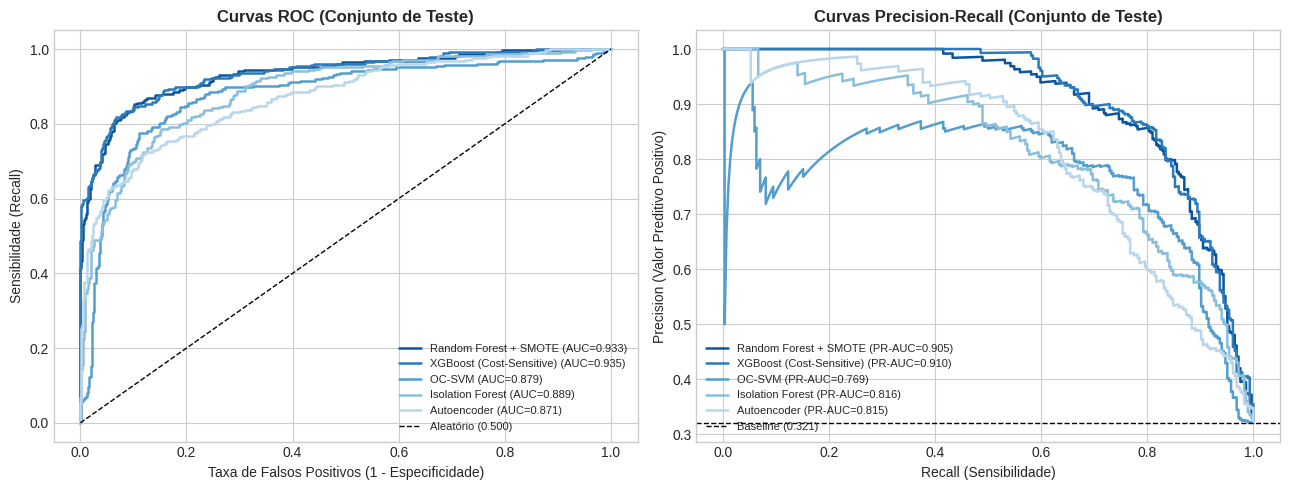

In [12]:
# %% [CÉLULA 12] Consolidação da Tabela 3, Estudo de Ablação e Curvas ROC + PR
if DATA_READY and len(results_list) > 0:
    df_results = pd.DataFrame(results_list).sort_values(by=METRICA_REFERENCIA, ascending=False).reset_index(drop=True)
    print('\n=== TABELA 3: Síntese das Métricas de Desempenho no Conjunto de Teste ===')
    display(df_results)
    df_results.to_csv(caminho_saida('tabela3_desempenho_modelos.csv', 'tabelas'), index=False)

    # Identifica os campeões de cada paradigma pelo MCC
    best_sup_name = df_results[df_results['Abordagem'] == 'Supervisionada'].iloc[0]['Model']
    best_oc_name  = df_results[df_results['Abordagem'] == 'One-Class'].iloc[0]['Model']
    print(f'🏆 Melhor Supervisionado ({METRICA_REFERENCIA}): {best_sup_name}')
    print(f'🏆 Melhor One-Class      ({METRICA_REFERENCIA}): {best_oc_name}')

    # --- Executa Estudo de Ablação da Variável Sintética 'percentual_curso_concluido' ---
    print('\n--- Estudo de Ablação: Impacto de percentual_curso_concluido (Multi-Seed) ---')
    df_ablacao = ablation_feature_sintetica(
        model_builder_fn=lambda s: XGBClassifier(
            **study_xgb.best_params, random_state=s, eval_metric='logloss', n_jobs=N_JOBS_CV
        ),
        X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test,
        feature_names=feature_names, seeds=SEEDS_ABLACAO
    )

    # --- Plota Curvas ROC e Precision-Recall Lado a Lado ---
    modelos_destaque = [best_sup_name, 'XGBoost (Cost-Sensitive)', best_oc_name, 'Isolation Forest', 'Autoencoder']
    modelos_destaque = list(dict.fromkeys([m for m in modelos_destaque if m in preds_store]))
    plot_roc_and_pr_curves(y_test, modelos_destaque, fname='roc_pr_comparativo.png')


=== Executando Bootstrap Pareado (2000 iterações) ===


,Model,MCC_mean,MCC_IC95,F1_mean,F1_IC95,Recall_mean,Recall_IC95,Specificity_mean,Specificity_IC95,AUC-ROC_mean,AUC-ROC_IC95
0,Random Forest + SMOTE,0.7533,[0.7037; 0.7988],0.8290,[0.7934; 0.8618],0.8027,[0.7553; 0.8481],0.9370,[0.9169; 0.9554],0.9332,[0.9122; 0.9517]
1,Random Forest + RandomOverSampler,0.7316,[0.6808; 0.7804],0.8164,[0.7799; 0.8513],0.8064,[0.7584; 0.8516],0.9203,[0.8986; 0.9408],0.9329,[0.9122; 0.9514]
2,Random Forest + RandomUnderSampler,0.7103,[0.6615; 0.7604],0.8068,[0.7705; 0.8416],0.8596,[0.8175; 0.8990],0.8720,[0.8458; 0.8982],0.9310,[0.9102; 0.9499]
3,Random Forest + NearMiss,0.5698,[0.5174; 0.6221],0.7170,[0.6784; 0.7557],0.8836,[0.8462; 0.9207],0.7256,[0.6876; 0.7628],0.8946,[0.8714; 0.9174]
4,Random Forest + SMOTETomek,0.7241,[0.6751; 0.7723],0.8092,[0.7737; 0.8444],0.7849,[0.7368; 0.8315],0.9269,[0.9054; 0.9468],0.9321,[0.9113; 0.9509]
5,Random Forest + SMOTEENN,0.7060,[0.6564; 0.7555],0.8020,[0.7650; 0.8374],0.8204,[0.7754; 0.8635],0.8937,[0.8693; 0.9175],0.9243,[0.9023; 0.9439]
6,XGBoost (Cost-Sensitive),0.7295,[0.6810; 0.7762],0.8179,[0.7835; 0.8499],0.8379,[0.7933; 0.8799],0.9005,[0.8769; 0.9237],0.9354,[0.9158; 0.9542]
7,OC-SVM,0.6583,[0.6048; 0.7093],0.7680,[0.7273; 0.8049],0.7708,[0.7218; 0.8192],0.8886,[0.8636; 0.9135],0.8792,[0.8495; 0.9052]
8,Isolation Forest,0.5858,[0.5305; 0.6411],0.7266,[0.6867; 0.7664],0.7961,[0.7500; 0.8431],0.8135,[0.7812; 0.8456],0.8887,[0.8635; 0.9120]
9,LOF,0.6128,[0.5566; 0.6673],0.7292,[0.6857; 0.7685],0.6935,[0.6391; 0.7444],0.9017,[0.8772; 0.9240],0.8612,[0.8332; 0.8890]


 Δ MCC (Random Forest + SMOTE vs OC-SVM): 0.0950 IC95% [0.0521; 0.1380] | p-valor = 9.9950e-04
 Δ MCC (XGBoost (Cost-Sensitive) vs OC-SVM): 0.0713 IC95% [0.0249; 0.1191] | p-valor = 1.9990e-03

=== Teste de DeLong (Comparação de Curvas ROC) ===


,Modelo A,Modelo B,AUC A,AUC B,Delta AUC,Z-stat,p-valor (bicaudal)
0,Random Forest + SMOTE,OC-SVM,0.9333,0.8789,0.0543,5.0419,0.0000
1,Random Forest + SMOTE,Isolation Forest,0.9333,0.8888,0.0445,4.7004,0.0000
2,Random Forest + SMOTE,Autoencoder,0.9333,0.8713,0.0620,5.5730,0.0000
3,XGBoost (Cost-Sensitive),OC-SVM,0.9355,0.8789,0.0565,5.3919,0.0000
4,XGBoost (Cost-Sensitive),Isolation Forest,0.9355,0.8888,0.0467,4.7790,0.0000
5,XGBoost (Cost-Sensitive),Autoencoder,0.9355,0.8713,0.0642,5.5407,0.0000



=== Teste de McNemar Pareado com Correção de Holm-Bonferroni ===


,Modelo 1,Modelo 2,Estatística McNemar,p_raw,p_Holm_Bonferroni
0,Random Forest + SMOTE,XGBoost (Cost-Sensitive),3.7812,0.0518,0.1527
1,Random Forest + SMOTE,OC-SVM,16.2976,0.0001,0.0004
2,Random Forest + SMOTE,Isolation Forest,41.9776,0.0000,0.0000
3,Random Forest + SMOTE,Autoencoder,27.0677,0.0000,0.0000
4,XGBoost (Cost-Sensitive),OC-SVM,6.2500,0.0124,0.0497
5,XGBoost (Cost-Sensitive),Isolation Forest,27.5625,0.0000,0.0000
6,XGBoost (Cost-Sensitive),Autoencoder,15.2583,0.0001,0.0005
7,OC-SVM,Isolation Forest,15.9186,0.0001,0.0004
8,OC-SVM,Autoencoder,3.8110,0.0509,0.1527
9,Isolation Forest,Autoencoder,1.5433,0.2141,0.2141



=== Expected Calibration Error (ECE) ===
  XGBoost (Cost-Sensitive)       | ECE = 0.1008
  Random Forest + SMOTE          | ECE = 0.0686
  OC-SVM                         | ECE = 0.2355
  Isolation Forest               | ECE = 0.0684


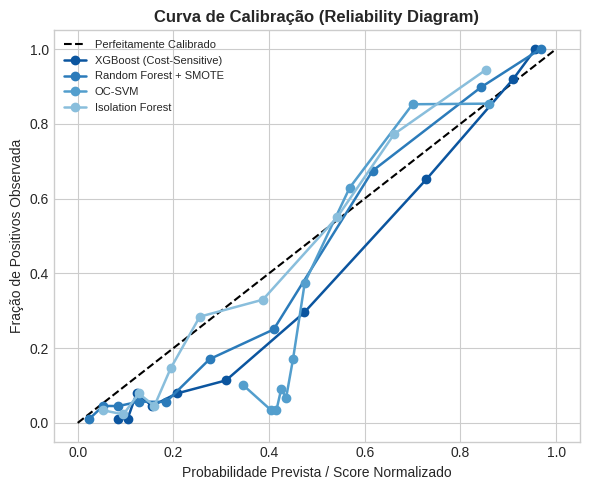

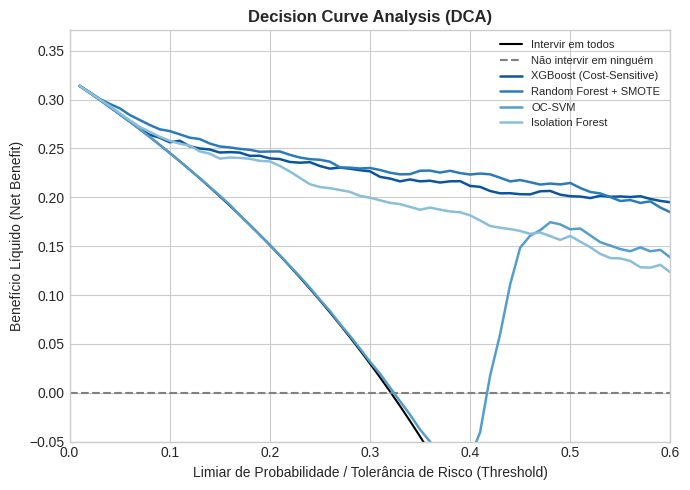

In [13]:
# %% [CÉLULA 13] Rigor Estatístico (Bootstrap Pareado, DeLong, McNemar-Holm) e Utilidade Prática
if DATA_READY and len(preds_store) > 0:
    print(f'=== Executando Bootstrap Pareado ({N_BOOT} iterações) ===')
    boot_results = paired_bootstrap(y_test, preds_store, n_boot=N_BOOT, seed=SEED)

    boot_rows = []
    for m_name, metrics_dict in boot_results.items():
        row = {'Model': m_name}
        for met_k in ['MCC', 'F1', 'Recall', 'Specificity', 'AUC-ROC']:
            if met_k in metrics_dict:
                mean_v, lo_v, hi_v = summarize_bootstrap(metrics_dict[met_k])
                row[f'{met_k}_mean'] = round(mean_v, 4)
                row[f'{met_k}_IC95'] = f'[{lo_v:.4f}; {hi_v:.4f}]'
        boot_rows.append(row)
    df_boot = pd.DataFrame(boot_rows)
    display(df_boot)
    df_boot.to_csv(caminho_saida('bootstrap_ic95.csv', 'tabelas'), index=False)

    # Diferença pareada de MCC entre Supervisionado e Melhor One-Class
    for ref_sup in [best_sup_name, 'XGBoost (Cost-Sensitive)']:
        if ref_sup in boot_results and best_oc_name in boot_results:
            delta_mcc = boot_results[ref_sup]['MCC'] - boot_results[best_oc_name]['MCC']
            d_mean, d_lo, d_hi = summarize_bootstrap(delta_mcc)
            p_boot = paired_delta_pvalue(delta_mcc)
            print(f' Δ MCC ({ref_sup} vs {best_oc_name}): {d_mean:.4f} IC95% [{d_lo:.4f}; {d_hi:.4f}] | p-valor = {p_boot:.4e}')

    # --- Teste Não Paramétrico de DeLong (AUC-ROC) ---
    print('\n=== Teste de DeLong (Comparação de Curvas ROC) ===')
    delong_rows = []
    for ref_sup in [best_sup_name, 'XGBoost (Cost-Sensitive)']:
        for oc_m in ['OC-SVM', 'Isolation Forest', 'Autoencoder']:
            if ref_sup in preds_store and oc_m in preds_store:
                auc1, auc2, z_stat, p_delong = delong_test(
                    y_test, preds_store[ref_sup]['y_prob'], preds_store[oc_m]['y_prob']
                )
                delong_rows.append({
                    'Modelo A': ref_sup, 'Modelo B': oc_m,
                    'AUC A': round(auc1, 4), 'AUC B': round(auc2, 4),
                    'Delta AUC': round(auc1 - auc2, 4), 'Z-stat': round(z_stat, 4),
                    'p-valor (bicaudal)': p_delong
                })
    df_delong = pd.DataFrame(delong_rows).drop_duplicates()
    display(df_delong)
    df_delong.to_csv(caminho_saida('teste_delong_auc.csv', 'tabelas'), index=False)

    # --- Teste de McNemar com Correção de Holm-Bonferroni ---
    print('\n=== Teste de McNemar Pareado com Correção de Holm-Bonferroni ===')
    pares_mcnemar = []
    for m1, m2 in combinations(modelos_destaque, 2):
        stat_mc, p_mc = mcnemar_test(y_test, preds_store[m1]['y_pred'], preds_store[m2]['y_pred'])
        pares_mcnemar.append({'Modelo 1': m1, 'Modelo 2': m2, 'Estatística McNemar': round(stat_mc, 4), 'p_raw': p_mc})
    df_mcnemar = pd.DataFrame(pares_mcnemar)
    df_mcnemar['p_Holm_Bonferroni'] = holm_correction(df_mcnemar['p_raw'].values)
    display(df_mcnemar)
    df_mcnemar.to_csv(caminho_saida('teste_mcnemar_holm.csv', 'tabelas'), index=False)

    # --- FIGURA 5 (Curva de Calibração + ECE) e FIGURA 6 (Decision Curve Analysis - DCA) ---
    modelos_curvas = ['XGBoost (Cost-Sensitive)', best_sup_name, 'OC-SVM', 'Isolation Forest']
    modelos_curvas = list(dict.fromkeys([m for m in modelos_curvas if m in preds_store]))
    probs_curvas = [preds_store[m]['y_prob'] for m in modelos_curvas]

    print('\n=== Expected Calibration Error (ECE) ===')
    for m_c, p_c in zip(modelos_curvas, probs_curvas):
        print(f'  {m_c:30s} | ECE = {compute_ece(y_test, p_c):.4f}')

    calibration_plot(y_test, probs_curvas, modelos_curvas, n_bins=10, fname='calibracao.png')
    decision_curve_analysis(y_test, probs_curvas, modelos_curvas, fname='dca.png')

=== Auditoria XAI Global: SHAP TreeExplainer (Supervisionado vs. One-Class) ===


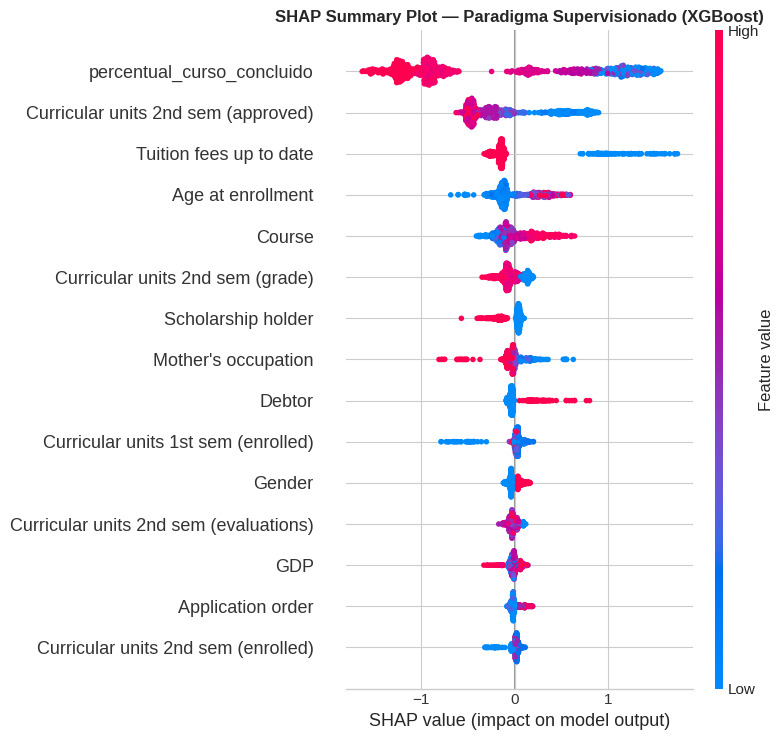

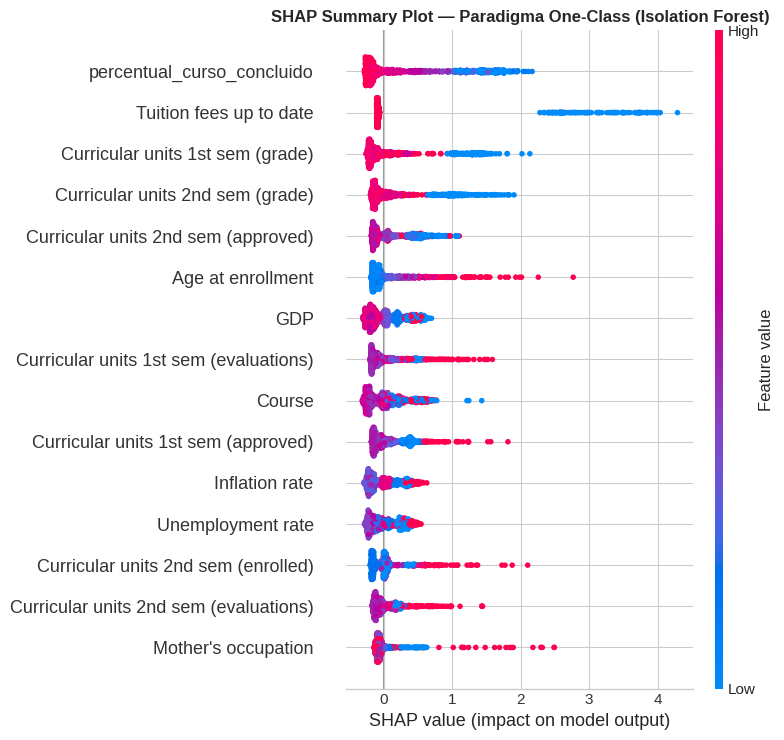


 Correlação de Postos de Spearman (Features Comuns N=20):
  ρ (rho) = 0.5940 | p-valor = 0.0058


,Feature,Mean_Abs_SHAP_Supervisionado,Mean_Abs_SHAP_OneClass,Rank_Supervisionado,Rank_OneClass
0,percentual_curso_concluido,0.9915,0.5199,1.0000,1.0000
1,Curricular units 2nd sem (approved),0.3973,0.2431,2.0000,5.0000
5,Tuition fees up to date,0.2857,0.4676,3.0000,2.0000
6,Age at enrollment,0.1902,0.2272,4.0000,6.0000
7,Course,0.1482,0.2038,5.0000,9.0000
2,Curricular units 2nd sem (grade),0.0893,0.3044,6.0000,4.0000
11,Mother's occupation,0.0708,0.1304,7.0000,15.0000
14,Curricular units 1st sem (enrolled),0.0582,0.1278,8.0000,17.0000
8,Curricular units 2nd sem (evaluations),0.0350,0.1496,9.0000,14.0000
17,GDP,0.0346,0.2107,10.0000,7.0000


In [14]:
# %% [CÉLULA 14] Auditoria XAI Global
if DATA_READY and 'XGBoost (Cost-Sensitive)' in models_store and 'Isolation Forest' in models_store:
    print('=== Auditoria XAI Global: SHAP TreeExplainer (Supervisionado vs. One-Class) ===')

    xgb_audit = models_store['XGBoost (Cost-Sensitive)']
    if_audit  = models_store['Isolation Forest']['model']
    top20_idx_audit = models_store['Isolation Forest']['top20_idx']
    top20_names_audit = [feature_names[i] for i in top20_idx_audit]

    # 1. SHAP Global — Modelo Supervisionado (XGBoost)
    explainer_xgb = shap.TreeExplainer(xgb_audit)
    shap_values_xgb = explainer_xgb.shap_values(X_test)
    if isinstance(shap_values_xgb, list):
        shap_values_xgb = shap_values_xgb[1]

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_xgb, X_test, feature_names=feature_names, max_display=15, show=False)
    plt.title('SHAP Summary Plot — Paradigma Supervisionado (XGBoost)', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig(caminho_saida('shap_summary_supervisionado.png', 'figuras'), dpi=200, bbox_inches='tight')
    plt.show()

    # 2. SHAP Global — Modelo One-Class (Isolation Forest)
    # Invertendo o sinal (-shap_values) para que valores positivos empurrem na direção de Anomalia/Evasão
    explainer_if = shap.TreeExplainer(if_audit)
    shap_values_if = -explainer_if.shap_values(X_test[:, top20_idx_audit])
    if isinstance(shap_values_if, list):
        shap_values_if = -shap_values_if[0]

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_if, X_test[:, top20_idx_audit], feature_names=top20_names_audit, max_display=15, show=False)
    plt.title('SHAP Summary Plot — Paradigma One-Class (Isolation Forest)', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig(caminho_saida('shap_summary_oneclass.png', 'figuras'), dpi=200, bbox_inches='tight')
    plt.show()

    # 3. Correlação de Postos de Spearman sobre as Features Comuns (Seção 4.4)
    mean_abs_shap_xgb_common = np.abs(shap_values_xgb[:, top20_idx_audit]).mean(axis=0)
    mean_abs_shap_if_common  = np.abs(shap_values_if).mean(axis=0)

    rho_spearman, p_spearman = stats.spearmanr(mean_abs_shap_xgb_common, mean_abs_shap_if_common)
    print(f'\n Correlação de Postos de Spearman (Features Comuns N={len(top20_idx_audit)}):')
    print(f'  ρ (rho) = {rho_spearman:.4f} | p-valor = {p_spearman:.4f}')

    df_shap_comp = pd.DataFrame({
        'Feature': top20_names_audit,
        'Mean_Abs_SHAP_Supervisionado': mean_abs_shap_xgb_common,
        'Mean_Abs_SHAP_OneClass': mean_abs_shap_if_common,
        'Rank_Supervisionado': stats.rankdata(-mean_abs_shap_xgb_common),
        'Rank_OneClass': stats.rankdata(-mean_abs_shap_if_common)
    }).sort_values(by='Rank_Supervisionado')
    display(df_shap_comp.head(10))
    df_shap_comp.to_csv(caminho_saida('shap_spearman_concordancia.csv', 'tabelas'), index=False)

=== Auditoria XAI Local: Estabilidade LIME Multi-Seed e Índice de Jaccard ===
 Avaliando 50 estudantes Verdadeiros Positivos em 5 sementes ([42, 43, 44, 45, 46])...


,Seed,Jaccard_Medio_Sup_vs_OneClass,Jaccard_DP,Baseline_Aleatorio
0,42,0.3444,0.0879,0.1862
1,43,0.3472,0.1071,0.1756
2,44,0.3232,0.0856,0.1662
3,45,0.3362,0.0922,0.1824
4,46,0.3454,0.0959,0.1755


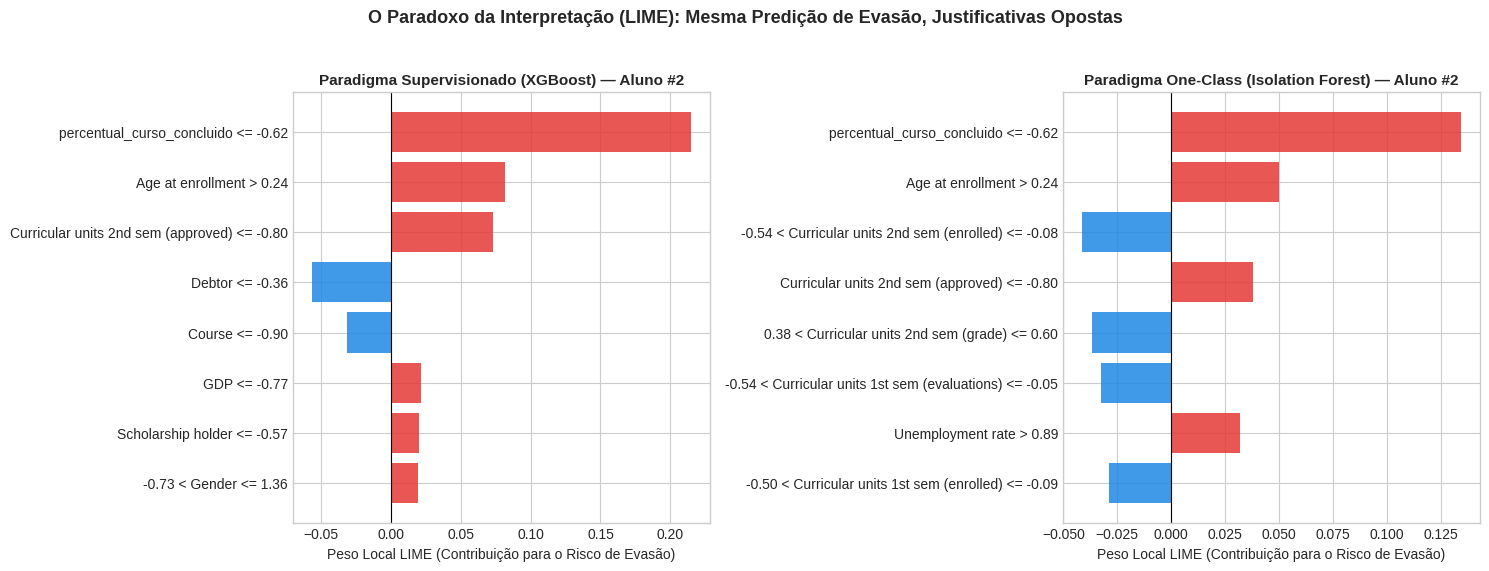

In [15]:
# %% [CÉLULA 15] O Paradoxo da Interpretação Local
if DATA_READY and 'XGBoost (Cost-Sensitive)' in models_store and 'Isolation Forest' in models_store:
    print('=== Auditoria XAI Local: Estabilidade LIME Multi-Seed e Índice de Jaccard ===')

    xgb_audit = models_store['XGBoost (Cost-Sensitive)']
    if_dict   = models_store['Isolation Forest']
    if_audit  = if_dict['model']
    range_if  = if_dict['range']
    top20_idx_audit = if_dict['top20_idx']

    # Wrapper que projeta as 35 features para o subespaço Top-20 do Isolation Forest e retorna probabilidades [P(Normal), P(Anomalia)]
    def predict_proba_if_full(X_input):
        X_arr = np.asarray(X_input, dtype=float)
        scores_anom = -if_audit.score_samples(X_arr[:, top20_idx_audit])
        p_anom = apply_score_range(scores_anom, range_if)
        return np.column_stack([1.0 - p_anom, p_anom])

    # Seleciona estudantes Verdadeiros Positivos nos quais AMBOS os paradigmas concordam com a evasão
    mask_tp_ambos = (y_test == 1) & (preds_store['XGBoost (Cost-Sensitive)']['y_pred'] == 1) & (preds_store['Isolation Forest']['y_pred'] == 1)
    idx_tp_ambos = np.where(mask_tp_ambos)[0]
    if len(idx_tp_ambos) == 0:
        idx_tp_ambos = np.where(y_test == 1)[0]

    n_amostras_lime = min(N_LIME_SAMPLES_R, len(idx_tp_ambos))
    amostras_audit = idx_tp_ambos[:n_amostras_lime]
    print(f' Avaliando {n_amostras_lime} estudantes Verdadeiros Positivos em {N_LIME_SEEDS} sementes ({SEEDS_LIME})...')

    jaccard_por_seed = []
    rng_base = np.random.RandomState(SEED)

    for s_lime in SEEDS_LIME:
        explainer_lime = LimeTabularExplainer(
            training_data=X_train,
            feature_names=feature_names,
            class_names=['Não Evadido', 'Evadido'],
            mode='classification',
            random_state=s_lime
        )
        jaccards_amostras = []
        jaccards_random   = []

        for idx_aluno in amostras_audit:
            x_inst = X_test[idx_aluno]
            exp_sup = explainer_lime.explain_instance(
                x_inst, xgb_audit.predict_proba, num_features=XAI_K_TOP, num_samples=N_LIME_SAMPLES
            )
            exp_occ = explainer_lime.explain_instance(
                x_inst, predict_proba_if_full, num_features=XAI_K_TOP, num_samples=N_LIME_SAMPLES
            )
            # Extração exata pelos índices via as_map() conforme Seção 3.6
            top_sup_set = set([feat_idx for feat_idx, _ in exp_sup.as_map()[1][:XAI_K_TOP]])
            top_occ_set = set([feat_idx for feat_idx, _ in exp_occ.as_map()[1][:XAI_K_TOP]])

            inter = len(top_sup_set & top_occ_set)
            union = len(top_sup_set | top_occ_set)
            jaccards_amostras.append(inter / union if union > 0 else 0.0)

            # Baseline aleatório pareado (sorteio sem reposição de K features entre as 35)
            rnd_a = set(rng_base.choice(len(feature_names), XAI_K_TOP, replace=False))
            rnd_b = set(rng_base.choice(len(feature_names), XAI_K_TOP, replace=False))
            jaccards_random.append(len(rnd_a & rnd_b) / len(rnd_a | rnd_b))

        jaccard_por_seed.append({
            'Seed': s_lime,
            'Jaccard_Medio_Sup_vs_OneClass': round(float(np.mean(jaccards_amostras)), 4),
            'Jaccard_DP': round(float(np.std(jaccards_amostras)), 4),
            'Baseline_Aleatorio': round(float(np.mean(jaccards_random)), 4)
        })

    df_lime_jaccard = pd.DataFrame(jaccard_por_seed)
    display(df_lime_jaccard)
    df_lime_jaccard.to_csv(caminho_saida('lime_jaccard_multiseed.csv', 'tabelas'), index=False)

    # --- FIGURA 9: O Paradoxo da Interpretação Local em um Estudante Verdadeiro Positivo (Aluno X) ---
    # Busca preferencialmente um perfil com vulnerabilidade socioeconômica (ex: Debtor=1 ou Age>=24) entre os TPs comuns
    idx_aluno_x = amostras_audit[0]
    for cand_idx in idx_tp_ambos:
        row_raw = X_test_raw.iloc[cand_idx]
        if row_raw.get('Debtor', 0) == 1 or row_raw.get('Scholarship holder', 1) == 0:
            idx_aluno_x = cand_idx
            break

    explainer_fig9 = LimeTabularExplainer(
        training_data=X_train, feature_names=feature_names,
        class_names=['Não Evadido', 'Evadido'], mode='classification', random_state=SEED
    )
    exp_sup_x = explainer_fig9.explain_instance(X_test[idx_aluno_x], xgb_audit.predict_proba, num_features=8, num_samples=N_LIME_SAMPLES)
    exp_occ_x = explainer_fig9.explain_instance(X_test[idx_aluno_x], predict_proba_if_full, num_features=8, num_samples=N_LIME_SAMPLES)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    for ax, exp_obj, titulo in [
        (axes[0], exp_sup_x, f'Paradigma Supervisionado (XGBoost) — Aluno #{idx_aluno_x}'),
        (axes[1], exp_occ_x, f'Paradigma One-Class (Isolation Forest) — Aluno #{idx_aluno_x}')
    ]:
        lista_exp = exp_obj.as_list(label=1)[::-1]
        nomes_f = [item[0] for item in lista_exp]
        pesos_f = [item[1] for item in lista_exp]
        cores_f = ['#E53935' if w > 0 else '#1E88E5' for w in pesos_f]
        ax.barh(nomes_f, pesos_f, color=cores_f, alpha=0.85)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_title(titulo, fontweight='bold', fontsize=11)
        ax.set_xlabel('Peso Local LIME (Contribuição para o Risco de Evasão)')

    plt.suptitle('O Paradoxo da Interpretação (LIME): Mesma Predição de Evasão, Justificativas Opostas',
                 fontsize=13, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.savefig(caminho_saida('lime_paradoxo_interpretacao_alunoX.png', 'figuras'), dpi=250, bbox_inches='tight')
    plt.show()


In [16]:

# %% [CÉLULA 16] Auditoria de Equidade  e Sistema Híbrido em Duas Camadas
if DATA_READY and len(preds_store) > 0:
    print('=== Seção 5.2: Auditoria de Equidade Algorítmica e Impacto Desproporcional (Disparate Impact) ===')
    modelos_auditoria = [best_sup_name, 'XGBoost (Cost-Sensitive)', best_oc_name, 'Isolation Forest']
    modelos_auditoria = list(dict.fromkeys([m for m in modelos_auditoria if m in preds_store]))

    df_fairness = fairness_audit(
        X_test_raw_df=X_test_raw,
        y_true=y_test,
        preds_store=preds_store,
        model_names=modelos_auditoria
    )

    print('\n=== Seção 6: Simulação Operacional do Sistema Complementar em Duas Camadas ===')
    df_duas_camadas = simular_sistema_duas_camadas(
        y_true=y_test,
        pred_sup=preds_store[best_sup_name]['y_pred'],
        pred_occ=preds_store['Isolation Forest']['y_pred'],
        nome_sup=best_sup_name,
        nome_occ='Isolation Forest'
    )

=== Seção 5.2: Auditoria de Equidade Algorítmica e Impacto Desproporcional (Disparate Impact) ===


,Recorte Demográfico / Social,Modelo,Selection Rate (Vulnerável),Selection Rate (Referência),Disparate Impact Ratio,FPR (Vulnerável),FPR (Referência),Diferença de FPR (Estigma)
0,Gender (Masculino=1 vs Feminino=0),Random Forest + SMOTE,0.4424,0.2199,2.0121,0.1257,0.0376,0.0882
1,Gender (Masculino=1 vs Feminino=0),XGBoost (Cost-Sensitive),0.4922,0.2482,1.9829,0.1943,0.0610,0.1333
2,Gender (Masculino=1 vs Feminino=0),OC-SVM,0.4393,0.2571,1.7085,0.1486,0.0962,0.0523
3,Gender (Masculino=1 vs Feminino=0),Isolation Forest,0.5016,0.3138,1.5982,0.2514,0.1596,0.0918
4,Debtor (Inadimplente=1 vs Em dia=0),Random Forest + SMOTE,0.5889,0.2679,2.1980,0.1316,0.0586,0.0730
5,Debtor (Inadimplente=1 vs Em dia=0),XGBoost (Cost-Sensitive),0.6556,0.3006,2.1806,0.2368,0.0906,0.1463
6,Debtor (Inadimplente=1 vs Em dia=0),OC-SVM,0.7556,0.2742,2.7554,0.5263,0.0835,0.4428
7,Debtor (Inadimplente=1 vs Em dia=0),Isolation Forest,0.8333,0.3308,2.5190,0.6316,0.1563,0.4753
8,Scholarship (Sem Bolsa=0 vs Bolsista=1),Random Forest + SMOTE,0.3746,0.0909,4.1208,0.0877,0.0149,0.0729
9,Scholarship (Sem Bolsa=0 vs Bolsista=1),XGBoost (Cost-Sensitive),0.4190,0.1039,4.0325,0.1353,0.0297,0.1056



=== Seção 6: Simulação Operacional do Sistema Complementar em Duas Camadas ===


,Quadrante de Intervenção,Total de Alunos (Teste),% da Coorte,Evadidos Reais Capturados,Taxa Real de Evasão no Grupo (%)
0,Q1: Risco Duplo (Tutoria + Assistência Social),235,26.6000,209,88.9000
1,Q2: Risco Acadêmico Puro (Foco em Tutoria/Moni...,31,3.5000,19,61.3000
2,Q3: Vulnerabilidade Estrutural Silenciosa (Rad...,103,11.6000,17,16.5000
3,Q4: Baixo Risco Global (Acompanhamento Regular),516,58.3000,39,7.6000


In [17]:
# %% [R1] Sanity checks: model set used in McNemar, 20-feature subspace, categorical encoding
print(modelos_destaque)
print('Critério no código: [melhor supervisionado por MCC, XGBoost, melhor OCC por MCC, Isolation Forest, Autoencoder]')
print('LOF ficou de fora porque não está na lista; Isolation Forest e Autoencoder foram fixados manualmente.')

print('\n=== ITEM 2: as 20 variáveis do subespaço (selecionadas por importância do RF no treino) ===')
top20_names_chk = [feature_names[i] for i in top20_idx]
for r, n in enumerate(top20_names_chk, 1):
    print(f'{r:2d}. {n}')
for v in ['Scholarship holder', 'Debtor', 'Gender']:
    print(f'{v!r:24s} dentro das 20? {v in top20_names_chk}')
print('\nRanking SHAP do Isolation Forest entre as 20 (Rank_OneClass):')
display(df_shap_comp.sort_values('Rank_OneClass')[['Feature', 'Rank_OneClass', 'Rank_Supervisionado']])

print('\n=== ITEM 6: codificação das categóricas ===')
cat_cands = ['Course', 'Nacionality', 'Nationality', 'Application mode', "Mother's occupation", "Father's occupation"]
for c in cat_cands:
    if c in X_train_raw.columns:
        print(f'{c:22s} dtype={X_train_raw[c].dtype} | distintos={X_train_raw[c].nunique()} | '
              f'min={X_train_raw[c].min()} max={X_train_raw[c].max()}')
print('Colunas object (passariam pelo LabelEncoder):', [c for c in preprocessor.df.columns if preprocessor.df[c].dtype == "object"])
print('Scaler:', type(scaler).__name__, '| ajustado só no treino (ver split_and_scale).')


['Random Forest + SMOTE', 'XGBoost (Cost-Sensitive)', 'OC-SVM', 'Isolation Forest', 'Autoencoder']
Critério no código: [melhor supervisionado por MCC, XGBoost, melhor OCC por MCC, Isolation Forest, Autoencoder]
LOF ficou de fora porque não está na lista; Isolation Forest e Autoencoder foram fixados manualmente.

=== ITEM 2: as 20 variáveis do subespaço (selecionadas por importância do RF no treino) ===
 1. percentual_curso_concluido
 2. Curricular units 2nd sem (approved)
 3. Curricular units 2nd sem (grade)
 4. Curricular units 1st sem (approved)
 5. Curricular units 1st sem (grade)
 6. Tuition fees up to date
 7. Age at enrollment
 8. Course
 9. Curricular units 2nd sem (evaluations)
10. Father's occupation
11. Curricular units 1st sem (evaluations)
12. Mother's occupation
13. Curricular units 2nd sem (enrolled)
14. Mother's qualification
15. Curricular units 1st sem (enrolled)
16. Application mode
17. Father's qualification
18. GDP
19. Unemployment rate
20. Inflation rate
'Scholarsh

,Feature,Rank_OneClass,Rank_Supervisionado
0,percentual_curso_concluido,1.0000,1.0000
5,Tuition fees up to date,2.0000,3.0000
4,Curricular units 1st sem (grade),3.0000,13.0000
2,Curricular units 2nd sem (grade),4.0000,6.0000
1,Curricular units 2nd sem (approved),5.0000,2.0000
6,Age at enrollment,6.0000,4.0000
17,GDP,7.0000,10.0000
10,Curricular units 1st sem (evaluations),8.0000,17.0000
7,Course,9.0000,5.0000
3,Curricular units 1st sem (approved),10.0000,15.0000



=== ITEM 6: codificação das categóricas ===
Course                 dtype=int64 | distintos=17 | min=1 max=17
Nacionality            dtype=int64 | distintos=17 | min=1 max=21
Application mode       dtype=int64 | distintos=18 | min=1 max=18
Mother's occupation    dtype=int64 | distintos=28 | min=1 max=32
Father's occupation    dtype=int64 | distintos=36 | min=1 max=46
Colunas object (passariam pelo LabelEncoder): []
Scaler: StandardScaler | ajustado só no treino (ver split_and_scale).


In [18]:
# %% [R2] Matched-feature XAI controls: shared 20 features and XGBoost trained on the 20 features
idx20 = list(top20_idx)
names20 = [feature_names[i] for i in idx20]
K = XAI_K_TOP
xgb_full = models_store['XGBoost (Cost-Sensitive)']
if_dict = models_store['Isolation Forest']
if_model, range_if = if_dict['model'], if_dict['range']

# ---------- Item 4a: XGBoost só com as 20 variáveis (mesmo espaço de busca do notebook) ----------
X_tr20, X_va20, X_te20 = X_train[:, idx20], X_val[:, idx20], X_test[:, idx20]
base_pos_weight = float((y_train == 0).sum()) / max(1, int((y_train == 1).sum()))

def objective_xgb20(trial):
    p = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.25, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 8),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', base_pos_weight * 0.7, base_pos_weight * 1.5),
        'random_state': SEED, 'eval_metric': 'logloss', 'n_jobs': N_JOBS_CV}
    clf = XGBClassifier(**p).fit(X_tr20, y_train)
    return f1_score(y_val, clf.predict(X_va20), zero_division=0)

study_xgb20 = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb20.optimize(objective_xgb20, n_trials=N_TRIALS_SUP)
xgb20 = XGBClassifier(**study_xgb20.best_params, random_state=SEED, eval_metric='logloss', n_jobs=N_JOBS_CV).fit(X_tr20, y_train)
yp20 = xgb20.predict(X_te20); pr20 = xgb20.predict_proba(X_te20)[:, 1]
print(f'XGBoost-20: MCC={matthews_corrcoef(y_test, yp20):.4f} | F1={f1_score(y_test, yp20):.4f} | AUC-ROC={roc_auc_score(y_test, pr20):.4f}')
print(f'XGBoost-35 (referência): MCC={matthews_corrcoef(y_test, preds_store["XGBoost (Cost-Sensitive)"]["y_pred"]):.4f}')

# ---------- Item 4b: Spearman (SHAP) ----------
sv20 = shap.TreeExplainer(xgb20).shap_values(X_te20)
if isinstance(sv20, list): sv20 = sv20[1]
m_xgb20 = np.abs(sv20).mean(0)
m_if = np.abs(shap_values_if).mean(0)                       # alinhado a top20_idx (Célula 14)
m_xgb35 = np.abs(shap_values_xgb[:, idx20]).mean(0)         # versão original, para comparação
rho35, p35 = stats.spearmanr(m_xgb35, m_if)
rho20, p20 = stats.spearmanr(m_xgb20, m_if)
rng = np.random.RandomState(SEED); B = 2000
r35, r20 = [], []
for _ in range(B):
    ii = rng.randint(0, X_te20.shape[0], X_te20.shape[0])
    r35.append(stats.spearmanr(np.abs(shap_values_xgb[ii][:, idx20]).mean(0), np.abs(shap_values_if[ii]).mean(0))[0])
    r20.append(stats.spearmanr(np.abs(sv20[ii]).mean(0), np.abs(shap_values_if[ii]).mean(0))[0])
ci = lambda a: (np.nanpercentile(a, 2.5), np.nanpercentile(a, 97.5))
print(f'\nSpearman XGB-35 vs IF: rho={rho35:.4f} (p={p35:.4f}) IC95%[{ci(r35)[0]:.3f}; {ci(r35)[1]:.3f}]')
print(f'Spearman XGB-20 vs IF: rho={rho20:.4f} (p={p20:.4f}) IC95%[{ci(r20)[0]:.3f}; {ci(r20)[1]:.3f}]')
pd.DataFrame({'Feature': names20, 'AbsSHAP_XGB20': m_xgb20, 'AbsSHAP_IF': m_if,
              'Rank_XGB20': stats.rankdata(-m_xgb20), 'Rank_IF': stats.rankdata(-m_if)}
             ).sort_values('Rank_XGB20').to_csv(caminho_saida('shap_spearman_xgb20_vs_if.csv', 'tabelas'), index=False)

# ---------- Itens 3 e 4c: LIME/Jaccard no espaço comum de 20 variáveis ----------
def jacc(a, b): return len(a & b) / len(a | b)
def top_set(exp, k): return {i for i, _ in exp.as_map()[1][:k]}

def make_fn_xgb_full_fixed(x_full):
    """XGB(35) explicado só nas 20 comuns: as outras 15 ficam fixas nos valores do aluno."""
    def fn(Z):
        F = np.tile(x_full, (len(Z), 1)); F[:, idx20] = Z
        return xgb_full.predict_proba(F)
    return fn

def fn_if20(Z):
    s = -if_model.score_samples(np.asarray(Z, dtype=float))
    p = apply_score_range(s, range_if)
    return np.column_stack([1.0 - p, p])

rb = np.random.RandomState(SEED)   # baseline correto: dois subconjuntos de 10 entre as 20
base20 = np.mean([jacc(set(rb.choice(20, K, replace=False)), set(rb.choice(20, K, replace=False))) for _ in range(20000)])
print(f'\nBaseline aleatório (10 de 20): {base20:.4f}')

rows = []
for s in SEEDS_LIME:
    expl = LimeTabularExplainer(training_data=X_tr20, feature_names=names20, class_names=['Não Evadido', 'Evadido'],
                                mode='classification', random_state=s)
    j_full, j_x20 = [], []
    for ia in amostras_audit:
        x20 = X_te20[ia]
        t_if = top_set(expl.explain_instance(x20, fn_if20, num_features=K, num_samples=N_LIME_SAMPLES), K)
        t_f = top_set(expl.explain_instance(x20, make_fn_xgb_full_fixed(X_test[ia]), num_features=K, num_samples=N_LIME_SAMPLES), K)
        t_x = top_set(expl.explain_instance(x20, xgb20.predict_proba, num_features=K, num_samples=N_LIME_SAMPLES), K)
        j_full.append(jacc(t_f, t_if)); j_x20.append(jacc(t_x, t_if))
    rows.append({'Seed': s,
                 'Jaccard_XGB35_restrito_20_vs_IF': round(np.mean(j_full), 4), 'DP_35r': round(np.std(j_full), 4),
                 'Jaccard_XGB20_vs_IF': round(np.mean(j_x20), 4), 'DP_20': round(np.std(j_x20), 4),
                 'Baseline_10de20': round(base20, 4)})
df_j20 = pd.DataFrame(rows); display(df_j20)
print(df_j20[['Jaccard_XGB35_restrito_20_vs_IF', 'Jaccard_XGB20_vs_IF']].mean().round(4))
df_j20.to_csv(caminho_saida('lime_jaccard_20_comuns.csv', 'tabelas'), index=False)


XGBoost-20: MCC=0.7101 | F1=0.8055 | AUC-ROC=0.9351
XGBoost-35 (referência): MCC=0.7292

Spearman XGB-35 vs IF: rho=0.5940 (p=0.0058) IC95%[0.519; 0.641]
Spearman XGB-20 vs IF: rho=0.6466 (p=0.0021) IC95%[0.564; 0.687]

Baseline aleatório (10 de 20): 0.3414


,Seed,Jaccard_XGB35_restrito_20_vs_IF,DP_35r,Jaccard_XGB20_vs_IF,DP_20,Baseline_10de20
0,42,0.4890,0.0894,0.5325,0.1142,0.3414
1,43,0.5016,0.0998,0.5266,0.1030,0.3414
2,44,0.5061,0.1017,0.5300,0.1093,0.3414
3,45,0.5068,0.1063,0.5254,0.1110,0.3414
4,46,0.5048,0.1075,0.5455,0.1061,0.3414


Jaccard_XGB35_restrito_20_vs_IF   0.5017
Jaccard_XGB20_vs_IF               0.5320
dtype: float64


In [19]:
# %% [R3] Sensitivity scenarios: early-information (no 2nd semester) and one-hot encoding of nominal variables
def _m(nome, abord, yp, score):
    return {'Modelo': nome, 'Abordagem': abord, 'MCC': round(matthews_corrcoef(y_test, yp), 4),
            'F1': round(f1_score(y_test, yp, zero_division=0), 4),
            'Recall': round(recall_score(y_test, yp, zero_division=0), 4),
            'AUC-ROC': round(roc_auc_score(y_test, score), 4)}

def thr(sv, yv):
    best_th, best_f1 = np.median(sv), -1.0
    for q in np.linspace(5, 95, 181):
        t = np.percentile(sv, q); f = f1_score(yv, (sv >= t).astype(int), zero_division=0)
        if f > best_f1: best_f1, best_th = f, t
    return best_th

def run_supervised(Xtr_raw, Xva_raw, Xte_raw, rotulo):
    out = []
    sc = StandardScaler().fit(Xtr_raw); a, b, c = sc.transform(Xtr_raw), sc.transform(Xva_raw), sc.transform(Xte_raw)
    bw = float((y_train == 0).sum()) / max(1, int((y_train == 1).sum()))
    def ox(t):
        p = dict(n_estimators=t.suggest_int('n_estimators', 100, 400, step=50), max_depth=t.suggest_int('max_depth', 3, 10),
                 learning_rate=t.suggest_float('learning_rate', 0.01, 0.25, log=True), subsample=t.suggest_float('subsample', 0.6, 1.0),
                 colsample_bytree=t.suggest_float('colsample_bytree', 0.6, 1.0), min_child_weight=t.suggest_int('min_child_weight', 1, 8),
                 scale_pos_weight=t.suggest_float('scale_pos_weight', bw * 0.7, bw * 1.5))
        m = XGBClassifier(**p, random_state=SEED, eval_metric='logloss', n_jobs=N_JOBS_CV).fit(a, y_train)
        return f1_score(y_val, m.predict(b), zero_division=0)
    st = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED)); st.optimize(ox, n_trials=N_TRIALS_SUP)
    m = XGBClassifier(**st.best_params, random_state=SEED, eval_metric='logloss', n_jobs=N_JOBS_CV).fit(a, y_train)
    out.append({**_m('XGBoost (Cost-Sensitive)', 'Supervisionada', m.predict(c), m.predict_proba(c)[:, 1]), 'Cenário': rotulo})
    def orf(t):
        pipe = ImbPipeline([('sc', StandardScaler()), ('sm', SMOTE(random_state=SEED)),
            ('clf', RandomForestClassifier(n_estimators=t.suggest_int('n_estimators', 100, 400, step=50), max_depth=t.suggest_int('max_depth', 5, 25),
                min_samples_split=t.suggest_int('min_samples_split', 2, 12), min_samples_leaf=t.suggest_int('min_samples_leaf', 1, 6),
                max_features=t.suggest_categorical('max_features', ['sqrt', 'log2']), random_state=SEED, n_jobs=N_JOBS_CV))])
        pipe.fit(Xtr_raw.values, y_train); return f1_score(y_val, pipe.predict(Xva_raw.values), zero_division=0)
    sr = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED)); sr.optimize(orf, n_trials=N_TRIALS_SUP)
    pipe = ImbPipeline([('sc', StandardScaler()), ('sm', SMOTE(random_state=SEED)),
                        ('clf', RandomForestClassifier(**sr.best_params, random_state=SEED, n_jobs=N_JOBS_CV))])
    pipe.fit(Xtr_raw.values, y_train)
    out.append({**_m('Random Forest + SMOTE', 'Supervisionada', pipe.predict(Xte_raw.values), pipe.predict_proba(Xte_raw.values)[:, 1]), 'Cenário': rotulo})
    return out

def run_occ(Xtr_raw, Xva_raw, Xte_raw, rotulo, k=20):
    sc = StandardScaler().fit(Xtr_raw); a, b, c = sc.transform(Xtr_raw), sc.transform(Xva_raw), sc.transform(Xte_raw)
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=N_JOBS_CV).fit(a, y_train)
    idx = np.argsort(rf.feature_importances_)[::-1][:min(k, a.shape[1])]
    An, Bv, Ct = a[y_train == 0][:, idx], b[:, idx], c[:, idx]
    out = []
    def go(nome, build, space_fn, score_fn):
        def obj(t):
            sv = score_fn(build(space_fn(t)).fit(An), Bv)
            return f1_score(y_val, (sv >= thr(sv, y_val)).astype(int), zero_division=0)
        st = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED)); st.optimize(obj, n_trials=N_TRIALS_OC)
        mdl = build(st.best_params).fit(An); th = thr(score_fn(mdl, Bv), y_val); s_te = score_fn(mdl, Ct)
        out.append({**_m(nome, 'One-Class', (s_te >= th).astype(int), s_te), 'Cenário': rotulo})
    go('OC-SVM', lambda p: OneClassSVM(**p),
       lambda t: {'kernel': t.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid']), 'nu': t.suggest_float('nu', 0.05, 0.50),
                  'gamma': t.suggest_categorical('gamma', ['scale', 'auto'])},
       lambda m_, X: -m_.decision_function(X))
    go('Isolation Forest', lambda p: IsolationForest(**p, contamination=contamination_rate, random_state=SEED, n_jobs=N_JOBS_CV),
       lambda t: {'n_estimators': t.suggest_int('n_estimators', 100, 400, step=50), 'max_samples': t.suggest_float('max_samples', 0.4, 1.0),
                  'max_features': t.suggest_float('max_features', 0.5, 1.0)},
       lambda m_, X: -m_.score_samples(X))
    go('LOF', lambda p: LocalOutlierFactor(**p, novelty=True, n_jobs=N_JOBS_CV),
       lambda t: {'n_neighbors': t.suggest_int('n_neighbors', 5, 50), 'metric': t.suggest_categorical('metric', ['euclidean', 'manhattan', 'minkowski'])},
       lambda m_, X: -m_.decision_function(X))
    return out

res = []
res += run_supervised(X_train_raw, X_val_raw, X_test_raw, 'Base (35 var.)')
res += run_occ(X_train_raw, X_val_raw, X_test_raw, 'Base (35 var.)')

# --- ITEM 5: temporalidade (matrícula + 1º semestre) ---
cols_temp = [c for c in X_train_raw.columns if '2nd sem' not in c and c != 'percentual_curso_concluido']
print(f'Item 5: {len(cols_temp)} variáveis mantidas; removidas:', sorted(set(X_train_raw.columns) - set(cols_temp)))
res += run_supervised(X_train_raw[cols_temp], X_val_raw[cols_temp], X_test_raw[cols_temp], 'Temporal (matrícula + 1º sem.)')
res += run_occ(X_train_raw[cols_temp], X_val_raw[cols_temp], X_test_raw[cols_temp], 'Temporal (matrícula + 1º sem.)')

# --- ITEM 6: one-hot nas categóricas (somente detectores OCC) ---
cat_found = [c for c in ['Course', 'Nacionality', 'Nationality', 'Application mode', "Mother's occupation", "Father's occupation"] if c in X_train_raw.columns]
print('Item 6: one-hot em', cat_found)
ohe = lambda df: pd.get_dummies(df, columns=cat_found, dtype=float)
Xtr_o = ohe(X_train_raw)
Xva_o = ohe(X_val_raw).reindex(columns=Xtr_o.columns, fill_value=0.0)
Xte_o = ohe(X_test_raw).reindex(columns=Xtr_o.columns, fill_value=0.0)
print('Colunas após one-hot:', Xtr_o.shape[1])
res += run_occ(Xtr_o, Xva_o, Xte_o, 'One-hot (OCC)')

df_rev = pd.DataFrame(res)[['Cenário', 'Modelo', 'Abordagem', 'MCC', 'F1', 'Recall', 'AUC-ROC']]
display(df_rev); df_rev.to_csv(caminho_saida('revisao_temporal_onehot.csv', 'tabelas'), index=False)


Item 5: 28 variáveis mantidas; removidas: ['Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'percentual_curso_concluido']
Item 6: one-hot em ['Course', 'Nacionality', 'Application mode', "Mother's occupation", "Father's occupation"]
Colunas após one-hot: 146


,Cenário,Modelo,Abordagem,MCC,F1,Recall,AUC-ROC
0,Base (35 var.),XGBoost (Cost-Sensitive),Supervisionada,0.7292,0.8179,0.8380,0.9355
1,Base (35 var.),Random Forest + SMOTE,Supervisionada,0.7530,0.8291,0.8028,0.9333
2,Base (35 var.),OC-SVM,One-Class,0.6584,0.7684,0.7711,0.8789
3,Base (35 var.),Isolation Forest,One-Class,0.5855,0.7267,0.7958,0.8888
4,Base (35 var.),LOF,One-Class,0.6131,0.7296,0.6937,0.8612
5,Temporal (matrícula + 1º sem.),XGBoost (Cost-Sensitive),Supervisionada,0.6855,0.7875,0.7958,0.9088
6,Temporal (matrícula + 1º sem.),Random Forest + SMOTE,Supervisionada,0.6958,0.7906,0.7711,0.9028
7,Temporal (matrícula + 1º sem.),OC-SVM,One-Class,0.5325,0.6861,0.7042,0.8329
8,Temporal (matrícula + 1º sem.),Isolation Forest,One-Class,0.4785,0.6581,0.7254,0.8158
9,Temporal (matrícula + 1º sem.),LOF,One-Class,0.4628,0.6245,0.5915,0.7843


In [20]:
# %% [R4] Equity audit: group sizes and bootstrap confidence intervals (DI, delta-FPR, delta-TPR)
grupos = {
    'Gender (male vs female)': np.asarray(X_test_raw['Gender'] == 1),
    'Debtor (yes vs no)': np.asarray(X_test_raw['Debtor'] == 1),
    'Scholarship (no vs yes)': np.asarray(X_test_raw['Scholarship holder'] == 0),
    'Late entrant (>=25 vs <25)': np.asarray(X_test_raw['Age at enrollment'] >= 25)}
mods = [best_sup_name, 'XGBoost (Cost-Sensitive)', best_oc_name, 'Isolation Forest']
n = len(y_test); B = 2000; rng = np.random.RandomState(SEED)
boot_idx = [rng.randint(0, n, n) for _ in range(B)]

def met(yp, yt, mv):
    mr = ~mv
    sv, sr = yp[mv].mean(), yp[mr].mean()
    nv, nr = mv & (yt == 0), mr & (yt == 0); pv, pr = mv & (yt == 1), mr & (yt == 1)
    rate = lambda m_: yp[m_].mean() if m_.sum() else np.nan
    return (sv / sr if sr > 0 else np.nan), rate(nv) - rate(nr), rate(pv) - rate(pr), sv, sr

rows = []
for g, mv in grupos.items():
    for m in mods:
        yp = np.asarray(preds_store[m]['y_pred'])
        di, dfpr, dtpr, sv, sr = met(yp, y_test, mv)
        bs = np.array([met(yp[ii], y_test[ii], mv[ii]) for ii in boot_idx])
        ic = lambda j: f'[{np.nanpercentile(bs[:, j], 2.5):.2f}; {np.nanpercentile(bs[:, j], 97.5):.2f}]'
        rows.append({'Grupo': g, 'Modelo': m,
                     'n vuln.': int(mv.sum()), 'n ref.': int((~mv).sum()),
                     'evadidos vuln.': int((mv & (y_test == 1)).sum()), 'evadidos ref.': int((~mv & (y_test == 1)).sum()),
                     'Sel. vuln.': round(sv, 4), 'Sel. ref.': round(sr, 4),
                     'DI': round(di, 2), 'DI IC95%': ic(0),
                     'ΔFPR': round(dfpr, 3), 'ΔFPR IC95%': ic(1),
                     'ΔTPR': round(dtpr, 3), 'ΔTPR IC95%': ic(2)})
df_fair2 = pd.DataFrame(rows); display(df_fair2)
df_fair2.to_csv(caminho_saida('fairness_ic_bootstrap.csv', 'tabelas'), index=False)


,Grupo,Modelo,n vuln.,n ref.,evadidos vuln.,evadidos ref.,Sel. vuln.,Sel. ref.,DI,DI IC95%,ΔFPR,ΔFPR IC95%,ΔTPR,ΔTPR IC95%
0,Gender (male vs female),Random Forest + SMOTE,321,564,146,138,0.4424,0.2199,2.0100,[1.66; 2.43],0.0880,[0.03; 0.14],0.0390,[-0.05; 0.13]
1,Gender (male vs female),XGBoost (Cost-Sensitive),321,564,146,138,0.4922,0.2482,1.9800,[1.66; 2.37],0.1330,[0.07; 0.20],0.0230,[-0.06; 0.11]
2,Gender (male vs female),OC-SVM,321,564,146,138,0.4393,0.2571,1.7100,[1.42; 2.06],0.0520,[-0.01; 0.11],0.0340,[-0.07; 0.13]
3,Gender (male vs female),Isolation Forest,321,564,146,138,0.5016,0.3138,1.6000,[1.36; 1.88],0.0920,[0.02; 0.17],0.0120,[-0.08; 0.11]
4,Debtor (yes vs no),Random Forest + SMOTE,90,795,52,232,0.5889,0.2679,2.2000,[1.78; 2.67],0.0730,[-0.03; 0.19],0.1470,[0.05; 0.24]
5,Debtor (yes vs no),XGBoost (Cost-Sensitive),90,795,52,232,0.6556,0.3006,2.1800,[1.81; 2.60],0.1460,[0.01; 0.29],0.1510,[0.08; 0.22]
6,Debtor (yes vs no),OC-SVM,90,795,52,232,0.7556,0.2742,2.7600,[2.33; 3.24],0.4430,[0.28; 0.61],0.1860,[0.09; 0.27]
7,Debtor (yes vs no),Isolation Forest,90,795,52,232,0.8333,0.3308,2.5200,[2.19; 2.87],0.4750,[0.31; 0.63],0.2260,[0.16; 0.29]
8,Scholarship (no vs yes),Random Forest + SMOTE,654,231,255,29,0.3746,0.0909,4.1200,[2.86; 6.86],0.0730,[0.04; 0.10],0.2030,[0.03; 0.38]
9,Scholarship (no vs yes),XGBoost (Cost-Sensitive),654,231,255,29,0.4190,0.1039,4.0300,[2.86; 6.34],0.1060,[0.07; 0.15],0.2420,[0.07; 0.42]


In [21]:
# %% [R5] Reproducibility table: search spaces and selected hyperparameters
espacos = [
 ('Random Forest (6 reamostradores)', 'n_estimators∈{100,150,…,400}; max_depth∈[5,25]; min_samples_split∈[2,12]; min_samples_leaf∈[1,6]; max_features∈{sqrt,log2}', 'rf_best_params'),
 ('XGBoost (Cost-Sensitive)', 'n_estimators∈{100,…,400}; max_depth∈[3,10]; learning_rate∈[0.01,0.25] (log); subsample∈[0.6,1]; colsample_bytree∈[0.6,1]; min_child_weight∈[1,8]; scale_pos_weight∈[0.7,1.5]×(n_neg/n_pos)', 'study_xgb'),
 ('OC-SVM', 'kernel∈{rbf,poly,sigmoid}; nu∈[0.05,0.50]; gamma∈{scale,auto}', 'study_ocsvm'),
 ('Isolation Forest', 'n_estimators∈{100,…,400}; max_samples∈[0.4,1.0]; max_features∈[0.5,1.0]', 'study_if'),
 ('LOF', 'n_neighbors∈[5,50]; metric∈{euclidean,manhattan,minkowski}', 'study_lof'),
 ('Autoencoder', 'encoding_dim∈{4,…,12}; hidden_dim∈{14,…,28}; dropout∈[0,0.3]; lr∈[5e-4,5e-3] (log)', 'study_ae')]
rows = []
for nome, esp, var in espacos:
    if var == 'rf_best_params':
        d = globals().get('rf_best_params', {})
        if d:
            for k_, v_ in d.items(): rows.append({'Modelo': k_, 'Espaço de busca': esp, 'Melhor configuração': str(v_)})
        else:
            rows.append({'Modelo': nome, 'Espaço de busca': esp, 'Melhor configuração': '(aplicar patch na Célula 10 e reexecutar)'})
    else:
        s_ = globals().get(var)
        rows.append({'Modelo': nome, 'Espaço de busca': esp, 'Melhor configuração': str(s_.best_params) if s_ is not None else '(estudo não encontrado)'})
rows.append({'Modelo': 'Protocolo comum', 'Espaço de busca': f'TPESampler(seed=42); objetivo = F1 na validação; trials: supervisionados={N_TRIALS_SUP}, OCC={N_TRIALS_OC}, AE={N_TRIALS_AE}; split 60/20/20 estratificado (seed 42)', 'Melhor configuração': '—'})
df_repro = pd.DataFrame(rows); pd.set_option('display.max_colwidth', 400); display(df_repro)
df_repro.to_csv(caminho_saida('tabela_reprodutibilidade_optuna.csv', 'tabelas'), index=False)


,Modelo,Espaço de busca,Melhor configuração
0,Random Forest (6 reamostradores),"n_estimators∈{100,150,…,400}; max_depth∈[5,25]; min_samples_split∈[2,12]; min_samples_leaf∈[1,6]; max_features∈{sqrt,log2}",(aplicar patch na Célula 10 e reexecutar)
1,XGBoost (Cost-Sensitive),"n_estimators∈{100,…,400}; max_depth∈[3,10]; learning_rate∈[0.01,0.25] (log); subsample∈[0.6,1]; colsample_bytree∈[0.6,1]; min_child_weight∈[1,8]; scale_pos_weight∈[0.7,1.5]×(n_neg/n_pos)","{'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.010254184026219162, 'subsample': 0.9283115765850268, 'colsample_bytree': 0.7479767150641807, 'min_child_weight': 4, 'scale_pos_weight': 2.242379729484781}"
2,OC-SVM,"kernel∈{rbf,poly,sigmoid}; nu∈[0.05,0.50]; gamma∈{scale,auto}","{'kernel': 'sigmoid', 'nu': 0.49873792277965506, 'gamma': 'scale'}"
3,Isolation Forest,"n_estimators∈{100,…,400}; max_samples∈[0.4,1.0]; max_features∈[0.5,1.0]","{'n_estimators': 200, 'max_samples': 0.9704285838459497, 'max_features': 0.8659969709057025}"
4,LOF,"n_neighbors∈[5,50]; metric∈{euclidean,manhattan,minkowski}","{'n_neighbors': 35, 'metric': 'minkowski'}"
5,Autoencoder,"encoding_dim∈{4,…,12}; hidden_dim∈{14,…,28}; dropout∈[0,0.3]; lr∈[5e-4,5e-3] (log)","{'encoding_dim': 8, 'hidden_dim': 26, 'dropout_rate': 0.05990213464750792, 'lr': 0.0016338208828908817}"
6,Protocolo comum,"TPESampler(seed=42); objetivo = F1 na validação; trials: supervisionados=40, OCC=40, AE=20; split 60/20/20 estratificado (seed 42)",—


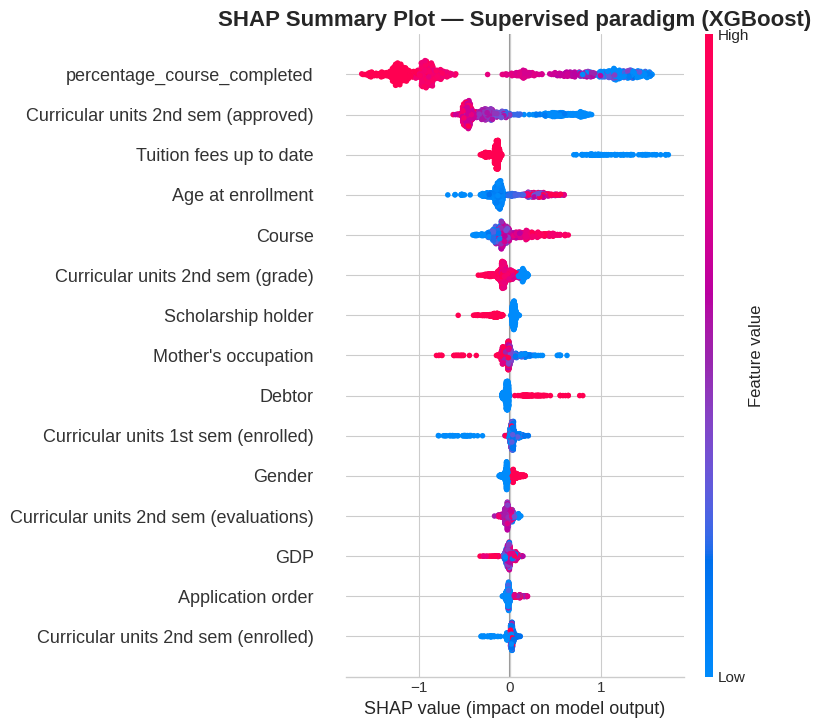

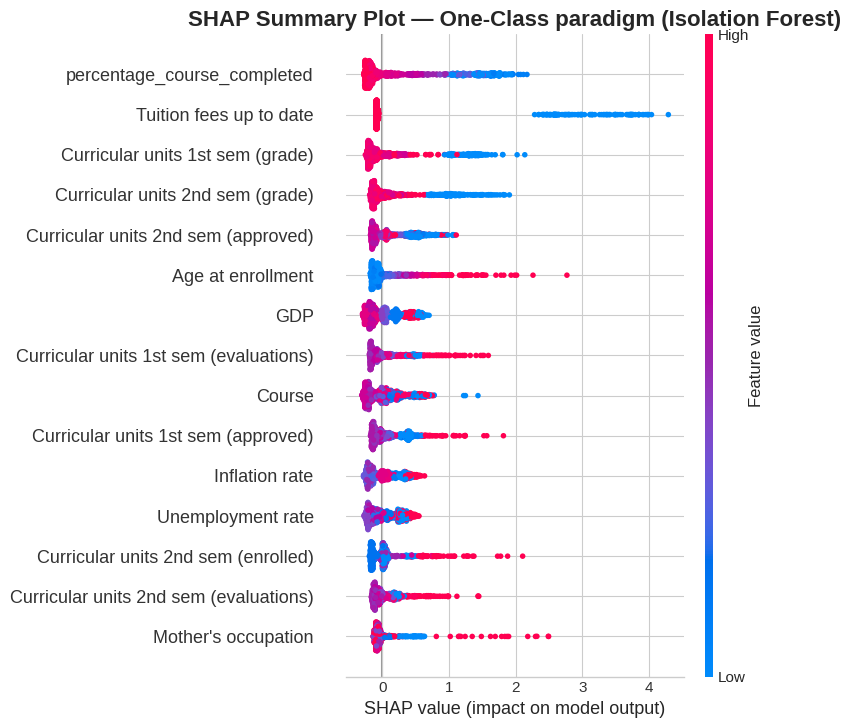

In [22]:
# %% [R6] Regenerated SHAP summary plots (English labels, larger fonts)
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14, 'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 13})
en = lambda L: [x.replace('percentual_curso_concluido', 'percentage_course_completed') for x in L]

plt.figure(figsize=(11, 7))
shap.summary_plot(shap_values_xgb, X_test, feature_names=en(feature_names), max_display=15, show=False)
plt.title('SHAP Summary Plot — Supervised paradigm (XGBoost)', fontweight='bold'); plt.tight_layout()
plt.savefig(caminho_saida('shap_summary_supervisionado.png', 'figuras'), dpi=300, bbox_inches='tight'); plt.show()

plt.figure(figsize=(11, 7))
shap.summary_plot(shap_values_if, X_test[:, top20_idx], feature_names=en([feature_names[i] for i in top20_idx]), max_display=15, show=False)
plt.title('SHAP Summary Plot — One-Class paradigm (Isolation Forest)', fontweight='bold'); plt.tight_layout()
plt.savefig(caminho_saida('shap_summary_oneclass.png', 'figuras'), dpi=300, bbox_inches='tight'); plt.show()


In [23]:
# %% [R7] Selected Random Forest hyperparameters per resampler
# Lê os melhores hiperparâmetros direto dos pipelines já treinados em models_store (não retreina nada).

rf_modelos = [k for k in models_store if k.startswith('Random Forest')]
assert rf_modelos, 'Rode a Célula 10 antes: models_store não tem os Random Forest.'

# 1) Conferência: o MCC deve reproduzir os valores da Tabela 3 (SMOTE = 0.7530)
from sklearn.metrics import matthews_corrcoef
print('=== Conferência de reprodução (MCC no teste) ===')
for k in rf_modelos:
    print(f'  {k:42s} MCC = {matthews_corrcoef(y_test, preds_store[k]["y_pred"]):.4f}')

# 2) Hiperparâmetros em formato de lista
print('\n=== Hiperparâmetros selecionados ===')
for k in rf_modelos:
    c = models_store[k].named_steps['clf']
    print(f'  {k:42s} n_estimators={c.n_estimators} | max_depth={c.max_depth} | '
          f'min_samples_split={c.min_samples_split} | min_samples_leaf={c.min_samples_leaf} | '
          f'max_features={c.max_features}')

# 3) Linhas prontas para colar na tabela do LaTeX (substituem as seis linhas vermelhas)
print('\n=== Linhas LaTeX ===')
for k in rf_modelos:
    c = models_store[k].named_steps['clf']
    nome = k.replace('Random Forest + ', '')
    print(f"\\quad + {nome} & & {c.n_estimators} trees; depth {c.max_depth}; "
          f"min.\\ split {c.min_samples_split}; min.\\ leaf {c.min_samples_leaf}; "
          f"\\texttt{{{c.max_features}}} \\\\")

=== Conferência de reprodução (MCC no teste) ===
  Random Forest + SMOTE                      MCC = 0.7530
  Random Forest + RandomOverSampler          MCC = 0.7313
  Random Forest + RandomUnderSampler         MCC = 0.7098
  Random Forest + NearMiss                   MCC = 0.5699
  Random Forest + SMOTETomek                 MCC = 0.7241
  Random Forest + SMOTEENN                   MCC = 0.7058

=== Hiperparâmetros selecionados ===
  Random Forest + SMOTE                      n_estimators=300 | max_depth=24 | min_samples_split=2 | min_samples_leaf=2 | max_features=log2
  Random Forest + RandomOverSampler          n_estimators=200 | max_depth=24 | min_samples_split=10 | min_samples_leaf=4 | max_features=sqrt
  Random Forest + RandomUnderSampler         n_estimators=150 | max_depth=21 | min_samples_split=10 | min_samples_leaf=1 | max_features=sqrt
  Random Forest + NearMiss                   n_estimators=300 | max_depth=5 | min_samples_split=7 | min_samples_leaf=3 | max_features=log2
  Ra